<h1 style="text-align: center;">Used Car Price Prediction - Syarah.com</h1>
<h3 style="text-align: center;">Athiyyah Nisrina Husna & Firsa Adam</h3>

---

## **Section 0. Setup**

### **0.1 Import Library**

In [39]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 1000)

In [40]:
# Palet warna
BLUE = '#3498db'   # warna utama
RED = '#e74c3c'    # warna pembanding / highlight

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.titlecolor': '#1a1a2e',
    'axes.labelcolor': '#1a1a2e',
    'xtick.color': '#444444',
    'ytick.color': '#444444',
    'axes.grid': True,
    'grid.color': '#d0d0d0',
    'axes.axisbelow': True,
})

from matplotlib.ticker import FuncFormatter
sar_fmt = FuncFormatter(lambda x, _: f'{x:,.0f}')  # format angka 1,200,000

In [41]:
df = pd.read_csv('../data/processed/cars_clean.csv')

# Car_Age dibuat untuk keperluan analisis; di tahap modeling, konversi dilakukan di dalam pipeline
df['Car_Age'] = (2021 - df['Year']).clip(lower=0)
df = df.drop(columns='Year')

assert df.shape == (5487, 12)
df.shape

(5487, 12)

## **Section 1. Exploratory Data Analysis**

Data yang digunakan pada tahap EDA ini adalah `cars_clean.csv`, yaitu hasil dari notebook `1_Data_Preparation.ipynb`. Dataset ini terdiri dari **5.487 listing** dan **12 kolom**, dengan kolom `Year` yang diganti menjadi fitur `Car_Age` (umur mobil saat data dikumpulkan pada tahun 2021) di awal notebook ini. Pada tahap modeling, konversi yang sama dilakukan di dalam pipeline. Dataset ini hanya berisi listing yang memiliki harga. Sebanyak 2.577 listing berstatus Negotiable tidak disertakan karena tidak memiliki nilai `Price`, dan disimpan terpisah sebagai data inferensi. Dengan demikian, seluruh analisis di notebook ini mencerminkan karakteristik listing berharga yang nantinya juga menjadi dasar pelatihan model.

Kolom `Price` yang digunakan merupakan harga yang dicantumkan pada listing berharga (non-negotiable), dalam satuan Riyal Saudi (SAR). Sebagian besar harga ini ditentukan oleh penjual di jalur iklan baris, sedangkan sebagian kecil ditetapkan oleh Syarah untuk mobil bekas yang dijualnya secara langsung. Seluruh nilai `Price` berada pada rentang 5.000–1.150.000 SAR, karena listing dengan harga di bawah 5.000 SAR telah dihapus sebagai kesalahan input. Kolom ini bertipe integer dan tidak memiliki nilai kosong.

In [42]:
df.dtypes

Make            object
Type            object
Origin          object
Color           object
Options         object
Engine_Size    float64
Fuel_Type       object
Gear_Type       object
Mileage        float64
Region          object
Price            int64
Car_Age          int64
dtype: object

### **1.1 Gambaran Umum Data**

#### **1.1.1 Sebaran Harga Mobil**


In [43]:
df['Price'].describe().round(0).apply('{:,.0f}'.format)

count        5,487
mean        79,811
std         76,227
min          5,000
25%         36,000
50%         58,000
75%         95,000
max      1,150,000
Name: Price, dtype: object

Harga mobil bekas pada dataset ini berkisar dari 5.000 hingga 1.150.000 SAR, dengan rata-rata sekitar 79.811 SAR dan median 58.000 SAR. Mean yang jauh lebih tinggi dari median, dengan selisih sekitar 21.800 SAR, menunjukkan distribusi harga yang condong ke kanan (right-skewed). Artinya, sebagian kecil listing dengan harga sangat tinggi, terutama mobil mewah, menarik nilai rata-rata ke atas. Karena itu, median lebih tepat digunakan untuk menggambarkan harga tipikal mobil bekas pada dataset ini.

Setengah dari seluruh listing berada pada rentang harga 36.000–95.000 SAR (Q1–Q3), sehingga mayoritas mobil yang dijual tergolong kelas menengah. Sebaliknya, harga maksimum mencapai 1.150.000 SAR, sekitar 12 kali lipat dari Q3. Hal ini menandakan rentang harga di sisi atas jauh lebih lebar dibandingkan di sisi bawah. Standar deviasi yang hampir sebesar mean (sekitar 76.227 SAR) juga menunjukkan variasi harga yang sangat tinggi antar listing.

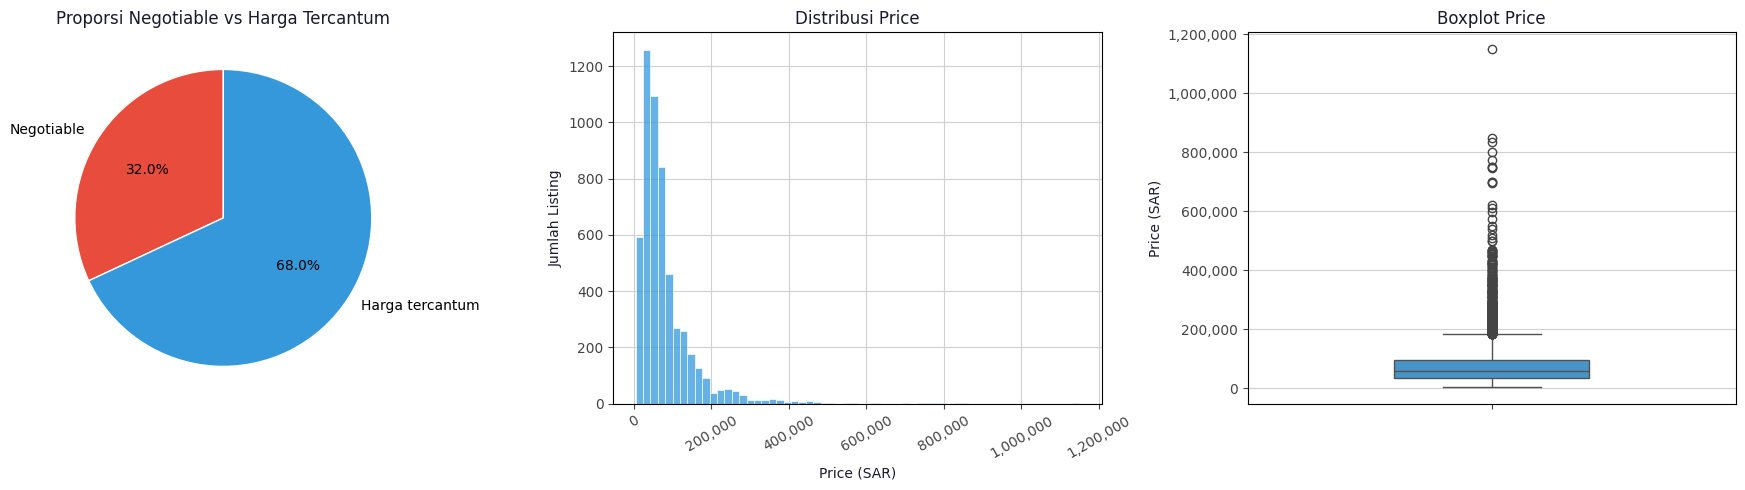

In [44]:
# Jumlah listing Negotiable diambil dari hasil Data Preparation
n_negotiable = len(pd.read_csv('../data/processed/cars_negotiable.csv'))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Proporsi Negotiable vs harga tercantum
axes[0].pie([n_negotiable, len(df)],
            labels=['Negotiable', 'Harga tercantum'],
            colors=[RED, BLUE], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white'})
axes[0].set_title('Proporsi Negotiable vs Harga Tercantum')

# Histogram
sns.histplot(df['Price'], bins=60, color=BLUE, edgecolor='white', ax=axes[1])
axes[1].set_title('Distribusi Price')
axes[1].set_xlabel('Price (SAR)')
axes[1].set_ylabel('Jumlah Listing')
axes[1].xaxis.set_major_formatter(sar_fmt)
axes[1].tick_params(axis='x', rotation=30)

# Boxplot
sns.boxplot(y=df['Price'], color=BLUE, width=0.4, ax=axes[2],
            flierprops={'markerfacecolor': 'none', 'markeredgecolor': '#444444'})
axes[2].set_title('Boxplot Price')
axes[2].set_ylabel('Price (SAR)')
axes[2].yaxis.set_major_formatter(sar_fmt)

plt.tight_layout()
plt.show()

Dari seluruh listing yang lolos tahap cleaning, termasuk listing mobil bekas yang dijual langsung oleh Syarah, sebanyak 32,0% (2.577 listing) berstatus Negotiable dan tidak mencantumkan harga, sedangkan 68,0% (5.487 listing) mencantumkan harga. Angka ini sedikit berbeda dari proporsi 33% pada bagian Business Understanding, yang dihitung khusus dari listing iklan baris sebelum proses cleaning. Hanya listing yang mencantumkan harga yang dapat digunakan untuk melatih dan mengevaluasi model, karena listing Negotiable tidak memiliki target. Proporsi Negotiable yang cukup besar ini menunjukkan bahwa model yang dibangun berpotensi memberikan manfaat langsung, yaitu menyediakan estimasi harga pasar bagi sepertiga listing yang dijual tanpa harga, yang dapat digunakan Syarah sebagai acuan awal penawaran beli.

Histogram menunjukkan distribusi harga yang sangat condong ke kanan (right-skewed). Sebagian besar listing terkonsentrasi pada rentang harga di bawah 100.000 SAR, dengan puncak frekuensi di kisaran 30.000–50.000 SAR. Setelah 200.000 SAR, jumlah listing menurun tajam, dan di atas 400.000 SAR hanya tersisa sedikit listing yang tersebar hingga 1.150.000 SAR.

Boxplot memperlihatkan bahwa 50% listing berada pada rentang 36.000–95.000 SAR, dengan median 58.000 SAR. Terdapat 373 listing (6,8%) yang berada di atas batas atas boxplot, yaitu 183.500 SAR (Q3 + 1,5 × IQR). Namun, listing-listing ini tidak dianggap sebagai kesalahan data, karena pada tahap Data Preparation harga tinggi telah diperiksa dan sebagian besar merupakan mobil mewah, seperti Mercedes G-Class, Bentley, dan Rolls-Royce, yang memang wajar memiliki harga tinggi.

In [45]:
print(f"Skewness Price: {df['Price'].skew():.2f}")
print(f"Kurtosis Price: {df['Price'].kurt():.2f}")

Skewness Price: 3.74
Kurtosis Price: 24.58


Hasil skewness (3,74) dan kurtosis (24,58) menunjukkan bahwa `Price` memiliki distribusi yang **sangat condong ke kanan** dengan ekor yang tebal. Kondisi ini perlu ditangani sebelum modeling, karena model regresi yang meminimalkan kuadrat error akan lebih terpengaruh oleh listing berharga tinggi. Sebagai ilustrasi, kesalahan prediksi sebesar 50.000 SAR dianggap sama besarnya, baik untuk mobil seharga 800.000 SAR maupun 40.000 SAR. Padahal, pada mobil pertama kesalahan tersebut hanya sekitar 6% dari harganya, sedangkan pada mobil kedua melebihi harga mobil itu sendiri. Akibatnya, model cenderung kurang akurat untuk mayoritas listing yang justru berada di rentang harga menengah ke bawah.

Untuk mengatasi hal ini, `Price` perlu ditransformasi agar distribusinya lebih simetris. Beberapa transformasi yang umum digunakan untuk data right-skewed dibandingkan di bawah ini, yaitu square root, cube root, log, log1p, Box-Cox, dan Yeo-Johnson.

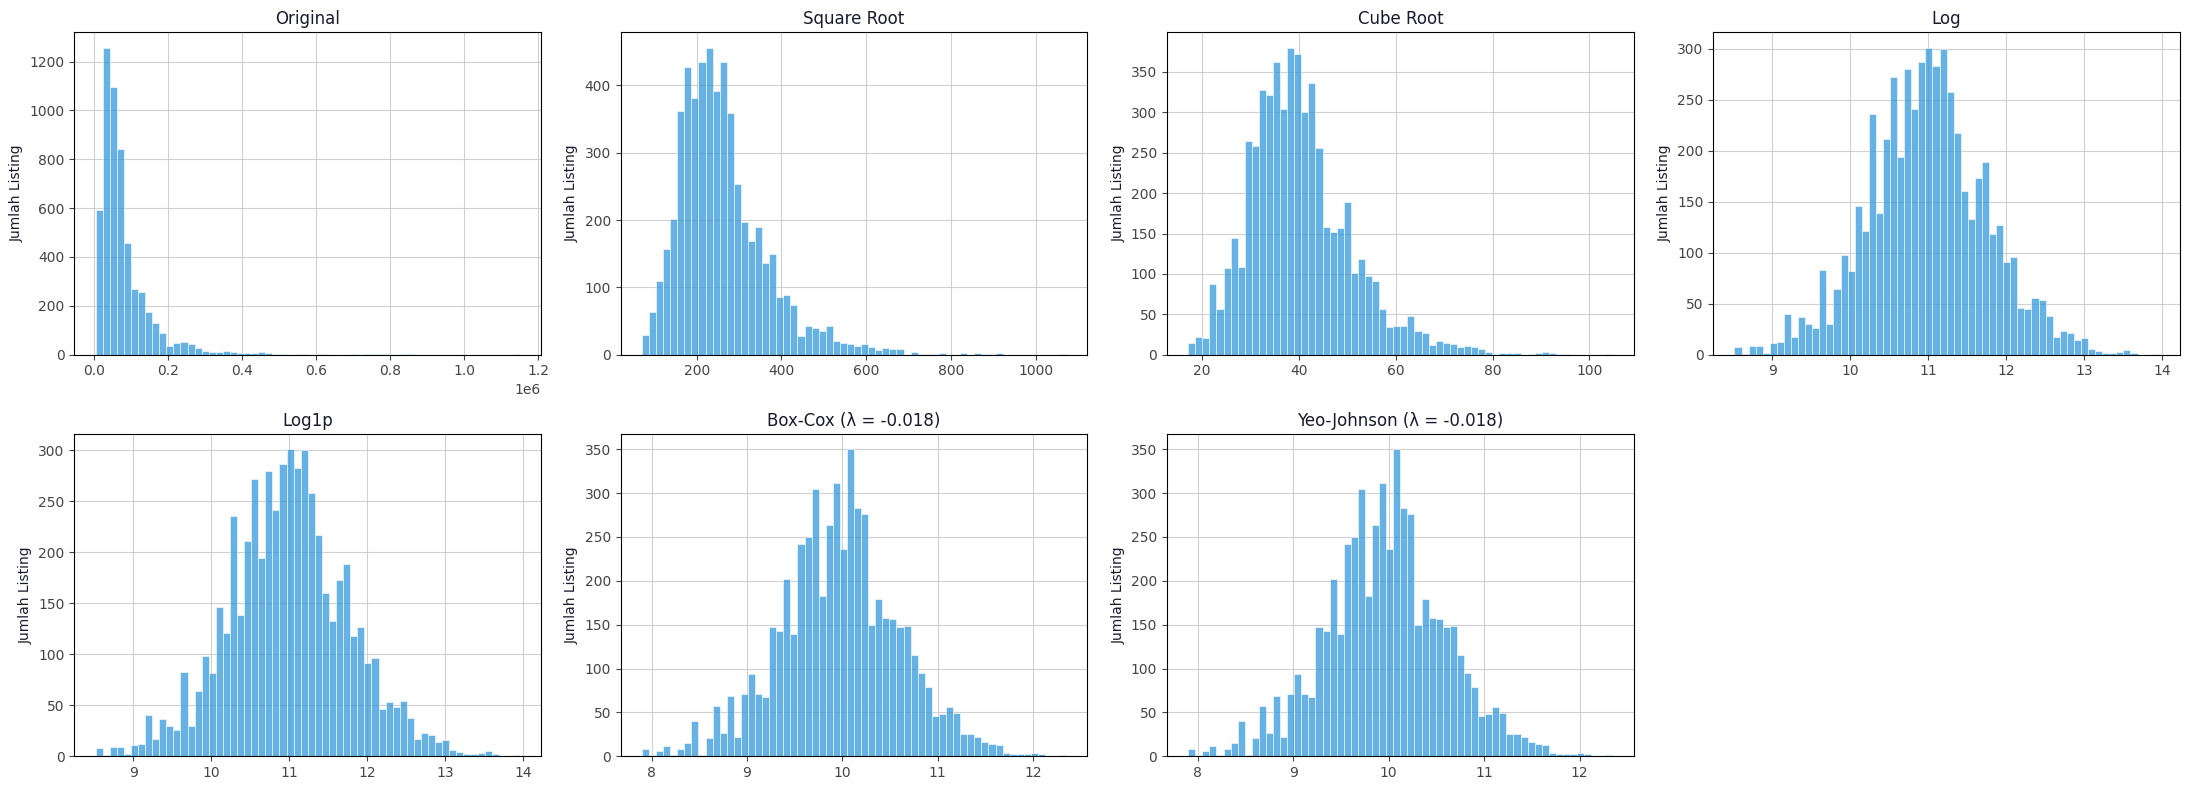

,Skewness,Kurtosis
Original,3.738,24.582
Square Root,1.497,4.049
Cube Root,0.969,1.845
Log,0.046,0.305
Log1p,0.046,0.305
Box-Cox (λ = -0.018),-0.001,0.303
Yeo-Johnson (λ = -0.018),-0.001,0.302


In [46]:
# Box-Cox dan Yeo-Johnson mengestimasi lambda dari data
# Di sini hanya digunakan sebagai pembanding, bukan untuk transformasi final
bc, lambda_bc = stats.boxcox(df['Price'])
yj, lambda_yj = stats.yeojohnson(df['Price'])

transforms = {
    'Original': df['Price'],
    'Square Root': np.sqrt(df['Price']),
    'Cube Root': np.cbrt(df['Price']),
    'Log': np.log(df['Price']),
    'Log1p': np.log1p(df['Price']),
    f'Box-Cox (λ = {lambda_bc:.3f})': pd.Series(bc),
    f'Yeo-Johnson (λ = {lambda_yj:.3f})': pd.Series(yj),
}

fig, axes = plt.subplots(2, 4, figsize=(22, 8))

for ax, (name, values) in zip(axes.flat, transforms.items()):
    sns.histplot(values, bins=60, color=BLUE, edgecolor='white', ax=ax)
    ax.set_title(name)
    ax.set_xlabel('')
    ax.set_ylabel('Jumlah Listing')

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

pd.DataFrame({
    'Skewness': {name: v.skew() for name, v in transforms.items()},
    'Kurtosis': {name: v.kurt() for name, v in transforms.items()},
}).round(3)

Square root dan cube root belum cukup untuk mengatasi kecondongan distribusi, karena skewness masih berada di kisaran 1–1,5. Keduanya menekan nilai besar lebih lemah dibandingkan logaritma, sehingga ekor kanan distribusi masih terlihat jelas. Sebaliknya, log, log1p, Box-Cox, dan Yeo-Johnson menghasilkan distribusi yang hampir simetris, dengan skewness dan kurtosis mendekati 0.

Box-Cox dan Yeo-Johnson bekerja dengan mencari nilai λ yang paling membuat data mendekati distribusi normal. Pada data ini, keduanya menghasilkan λ = −0,018, yang sangat dekat dengan 0. Box-Cox dengan λ = 0 secara matematis sama dengan transformasi logaritma, sehingga hasil ini menunjukkan bahwa transformasi logaritma merupakan bentuk yang paling sesuai untuk `Price`.

Berdasarkan hasil tersebut, transformasi logaritma dipilih dibandingkan Box-Cox dan Yeo-Johnson. Hasil ketiganya hampir sama, tetapi transformasi logaritma tidak perlu mengestimasi parameter dari data, sehingga tidak berisiko menimbulkan data leakage dan dapat diterapkan langsung pada data baru. Transformasi logaritma juga lebih mudah diinterpretasikan, karena perubahan dalam skala log mencerminkan perubahan harga secara persentase. Hal ini sejalan dengan penurunan harga mobil bekas akibat umur dan pemakaian yang umumnya bersifat persentase, bukan nominal yang sama untuk setiap mobil.

Di antara log dan log1p, hasil keduanya identik pada data ini, karena harga minimum adalah 5.000 SAR sehingga penambahan angka 1 tidak berpengaruh. Log1p dipilih sebagai praktik umum karena tetap aman digunakan jika terdapat nilai 0, misalnya pada data baru di kemudian hari.

Transformasi hanya diterapkan pada target selama proses training, lalu hasil prediksi dikembalikan ke satuan SAR menggunakan fungsi kebalikannya (expm1), sehingga hasil akhir dan metrik evaluasi tetap dapat diinterpretasikan dalam satuan harga aslinya. Pengaruh transformasi ini juga akan dibuktikan pada tahap modeling, dengan membandingkan performa model dengan dan tanpa transformasi log.

#### **1.1.2 Sebaran Umur, Jarak Tempuh, dan Ukuran Mesin**

Bagian ini melihat distribusi tiga fitur numerik, yaitu `Car_Age`, `Mileage`, dan `Engine_Size`, untuk memahami karakteristik mobil yang dijual sebelum melihat hubungannya dengan `Price`. Nilai kosong pada `Mileage` (387 baris) dan `Engine_Size` (1.189 baris) diabaikan pada perhitungan dan visualisasi di bagian ini.

In [47]:
num_cols = ['Car_Age', 'Mileage', 'Engine_Size']

num_stats = df[num_cols].describe().T
num_stats['skewness'] = df[num_cols].skew()
num_stats['kurtosis'] = df[num_cols].kurt()
num_stats['missing'] = df[num_cols].isna().sum()

num_stats.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,missing
Car_Age,5487.0,6.25,5.15,0.0,3.0,5.0,8.0,58.0,2.70,12.87,0
Mileage,5100.0,136634.35,108915.81,100.0,61000.0,109000.0,190000.0,900000.0,1.49,3.53,387
Engine_Size,4298.0,3.09,1.49,1.0,2.0,2.7,4.0,9.0,0.89,0.37,1189


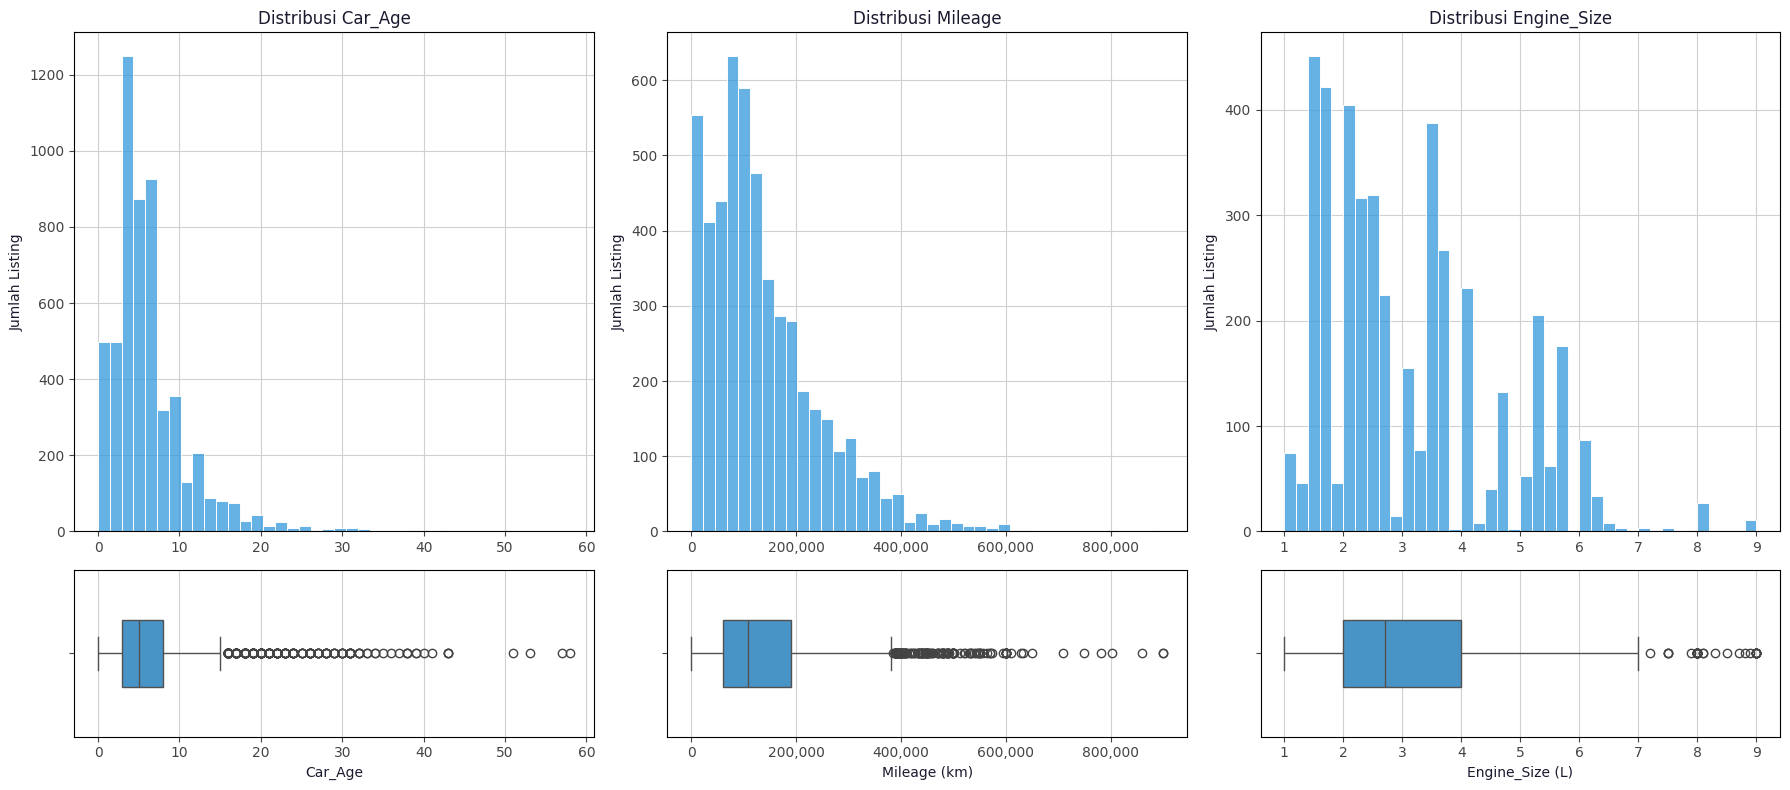

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8),
                         gridspec_kw={'height_ratios': [3, 1]})

for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=40, color=BLUE, edgecolor='white', ax=axes[0, i])
    axes[0, i].set_title(f'Distribusi {col}')
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylabel('Jumlah Listing')

    sns.boxplot(x=df[col], color=BLUE, width=0.4, ax=axes[1, i],
                flierprops={'markerfacecolor': 'none', 'markeredgecolor': '#444444'})

axes[0, 1].xaxis.set_major_formatter(sar_fmt)
axes[1, 1].xaxis.set_major_formatter(sar_fmt)
axes[1, 1].set_xlabel('Mileage (km)')
axes[1, 2].set_xlabel('Engine_Size (L)')

plt.tight_layout()
plt.show()

In [49]:
high_mileage = df[df['Mileage'] > 383_500]
print(f"Listing Mileage > 383.500 km: {len(high_mileage)}")
print(f"Median Car_Age: {high_mileage['Car_Age'].median():.0f} tahun")
print(f"Car_Age >= 10 tahun: {(high_mileage['Car_Age'] >= 10).mean():.0%}")

high_engine = df[df['Engine_Size'] > 7]
print(f"\nListing Engine_Size > 7,0 L: {len(high_engine)}")
high_engine['Type'].value_counts().head(5)

Listing Mileage > 383.500 km: 165
Median Car_Age: 14 tahun
Car_Age >= 10 tahun: 79%

Listing Engine_Size > 7,0 L: 46


Type
Yukon      4
Tahoe      4
LX         3
Marquis    3
F150       2
Name: count, dtype: int64

Kolom `Car_Age` memiliki distribusi yang condong ke kanan (right-skewed) dengan skewness 2,70. Sebagian besar listing merupakan mobil berumur muda, dengan median umur 5 tahun, setengah dari listing berumur 3–8 tahun, dan sekitar 79% listing berumur 8 tahun ke bawah. Sebaliknya, mobil berumur tua jumlahnya sedikit tetapi tersebar hingga 58 tahun, sehingga membentuk ekor panjang di sisi kanan. Kurtosis sebesar 12,87 juga menunjukkan ekor distribusi yang tebal. Terdapat 267 listing di atas batas atas boxplot (sekitar 15,5 tahun). Listing ini bukan kesalahan data, melainkan mobil berumur tua yang memang masih dijual.

Kolom `Mileage` memiliki distribusi yang condong ke kanan (right-skewed) dengan skewness 1,49. Setengah dari listing memiliki jarak tempuh 61.000–190.000 km, dengan median 109.000 km. Terdapat 165 listing di atas batas atas boxplot (383.500 km) dengan nilai maksimum 900.000 km. Listing ini didominasi mobil berumur tua, dengan median umur 14 tahun dan 79% di antaranya berumur 10 tahun ke atas, sehingga jarak tempuh yang tinggi masih wajar. Nilai `Mileage` yang tidak wajar juga telah ditangani pada tahap Data Preparation, sehingga nilai-nilai yang tersisa masih berada dalam batas yang mungkin terjadi.

Kolom `Engine_Size` tidak terdistribusi secara kontinu, melainkan mengelompok pada ukuran mesin standar yang umum diproduksi pabrikan, seperti 1,6 L, 2,0 L, 2,5 L, 3,5 L, dan 5,3 L. Pola ini terbentuk karena setiap model mobil hanya tersedia dalam beberapa varian mesin tertentu. Distribusinya sedikit condong ke kanan (skewness 0,89), dengan mayoritas mobil bermesin 2,0–4,0 L. Terdapat 46 listing di atas 7,0 L, yang didominasi SUV dan truk besar seperti Chevrolet Tahoe, GMC Yukon, dan Lexus LX. Meskipun model-model ini memang bermesin besar, kapasitas di atas 7,0 L tetap jarang ditemukan pada model tersebut, sehingga sebagian nilai ini kemungkinan merupakan kesalahan input yang telah dicatat sebagai keterbatasan data pada tahap Data Preparation.

#### **1.1.3 Sebaran Merek, Model, dan Karakteristik Lainnya**

Bagian ini melihat distribusi delapan fitur kategorikal, yaitu `Origin`, `Options`, `Fuel_Type`, `Gear_Type`, `Color`, `Region`, `Make`, dan `Type`. Agar grafik tetap mudah dibaca, visualisasi dibagi berdasarkan jumlah kategorinya. Fitur dengan kardinalitas rendah (2–3 kategori) ditampilkan dalam satu grid, `Color` dan `Region` ditampilkan seluruh kategorinya dalam grafik horizontal, sedangkan `Make` dan `Type` yang memiliki kardinalitas tinggi hanya ditampilkan 15 kategori teratas. Proporsi setiap kategori dihitung dari listing yang tidak memiliki nilai kosong pada kolom tersebut.

In [50]:
cat_cols = ['Origin', 'Options', 'Fuel_Type', 'Gear_Type', 'Color', 'Region', 'Make', 'Type']

pd.DataFrame({
    'n_unique': df[cat_cols].nunique(),
    'top': df[cat_cols].mode().iloc[0],
    'top_pct': [df[col].value_counts(normalize=True).iloc[0] * 100 for col in cat_cols],
    'n_rare (<10)': [(df[col].value_counts() < 10).sum() for col in cat_cols],
    'missing': df[cat_cols].isna().sum(),
}).round(1)

,n_unique,top,top_pct,n_rare (<10),missing
Origin,3,Saudi,75.3,0,26
Options,3,Full,38.3,0,39
Fuel_Type,3,Gas,98.0,0,0
Gear_Type,2,Automatic,89.3,0,18
Color,15,White,42.2,2,0
Region,27,Riyadh,42.1,5,0
Make,60,Toyota,22.9,23,0
Type,385,Accent,3.8,289,0


Delapan fitur kategorikal memiliki jumlah kategori yang sangat beragam, mulai dari 2 kategori pada `Gear_Type` hingga 385 kategori pada `Type`. Nilai kosong hanya ditemukan pada `Origin` (26 baris), `Options` (39 baris), dan `Gear_Type` (18 baris), dengan jumlah yang sangat kecil dibandingkan total data. Fitur `Color`, `Region`, `Make`, dan `Type` memiliki kategori dengan kurang dari 10 listing, terutama `Type` dengan 289 kategori langka. Perbedaan jumlah kategori ini menjadi dasar pengelompokan visualisasi pada bagian berikutnya.

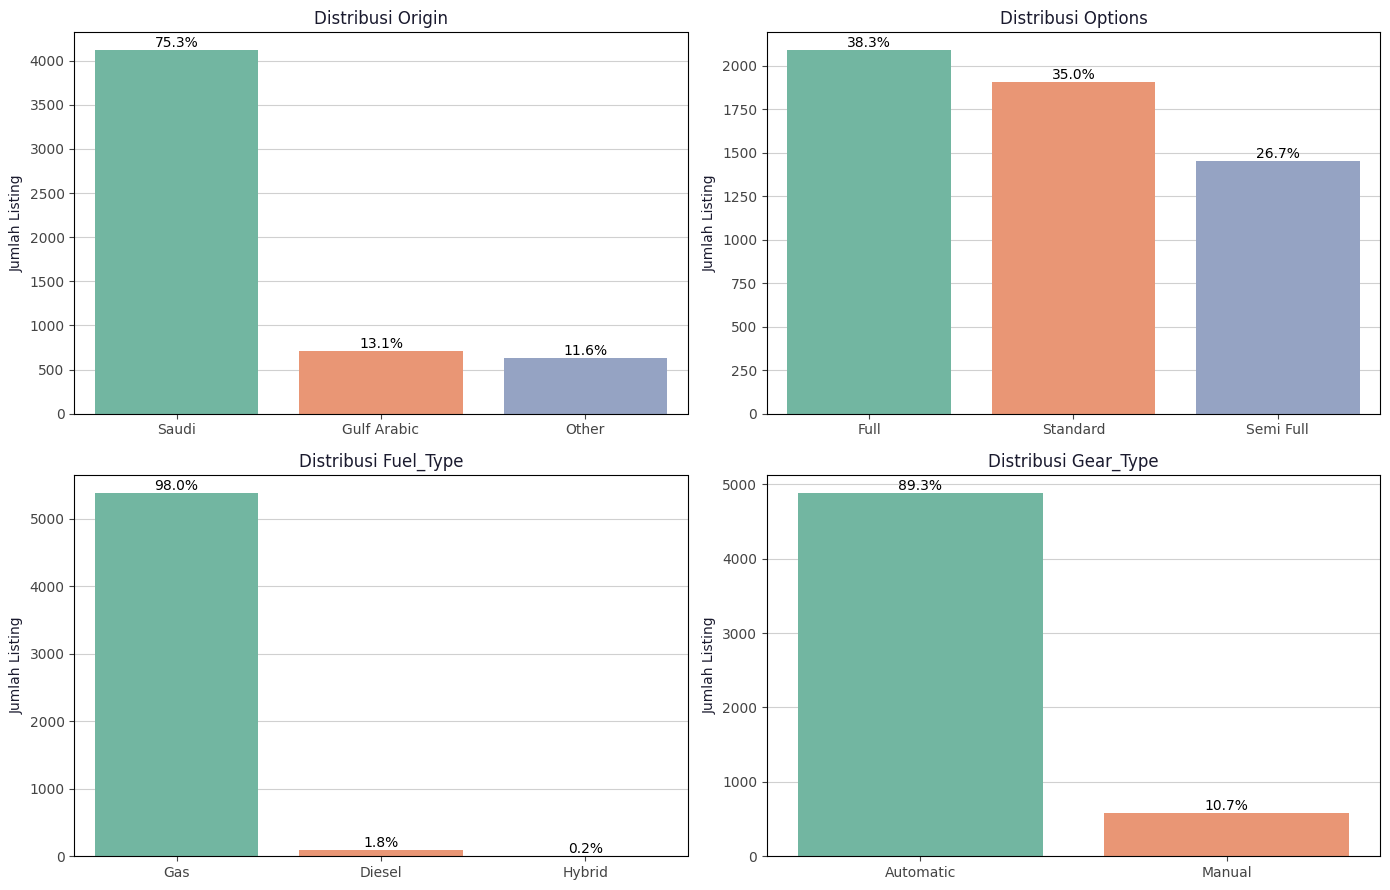

In [51]:
low_card_cols = ['Origin', 'Options', 'Fuel_Type', 'Gear_Type']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flat, low_card_cols):
    order = df[col].value_counts().index
    sns.countplot(x=df[col], order=order, hue=df[col], hue_order=order,
                  palette='Set2', legend=False, ax=ax)
    n_valid = df[col].notna().sum()
    for container in ax.containers:
        ax.bar_label(container, labels=[f'{v / n_valid:.1%}' for v in container.datavalues])
    ax.set_title(f'Distribusi {col}')
    ax.set_xlabel('')
    ax.set_ylabel('Jumlah Listing')

plt.tight_layout()
plt.show()

Pada fitur dengan kardinalitas rendah (jumlah kategori sedikit), sebagian besar distribusinya tidak seimbang. Mayoritas listing merupakan mobil asal Saudi (75,3%), bertransmisi otomatis (89,3%), dan berbahan bakar bensin (98,0%). Kolom `Fuel_Type` menjadi yang paling timpang, dengan Diesel hanya 1,8% dan Hybrid hanya 0,2% (11 listing), sehingga variasi informasi dari kolom ini sangat terbatas. Sebaliknya, kolom `Options` memiliki distribusi yang paling merata, dengan proporsi Full 38,3%, Standard 35,0%, dan Semi Full 26,7%.

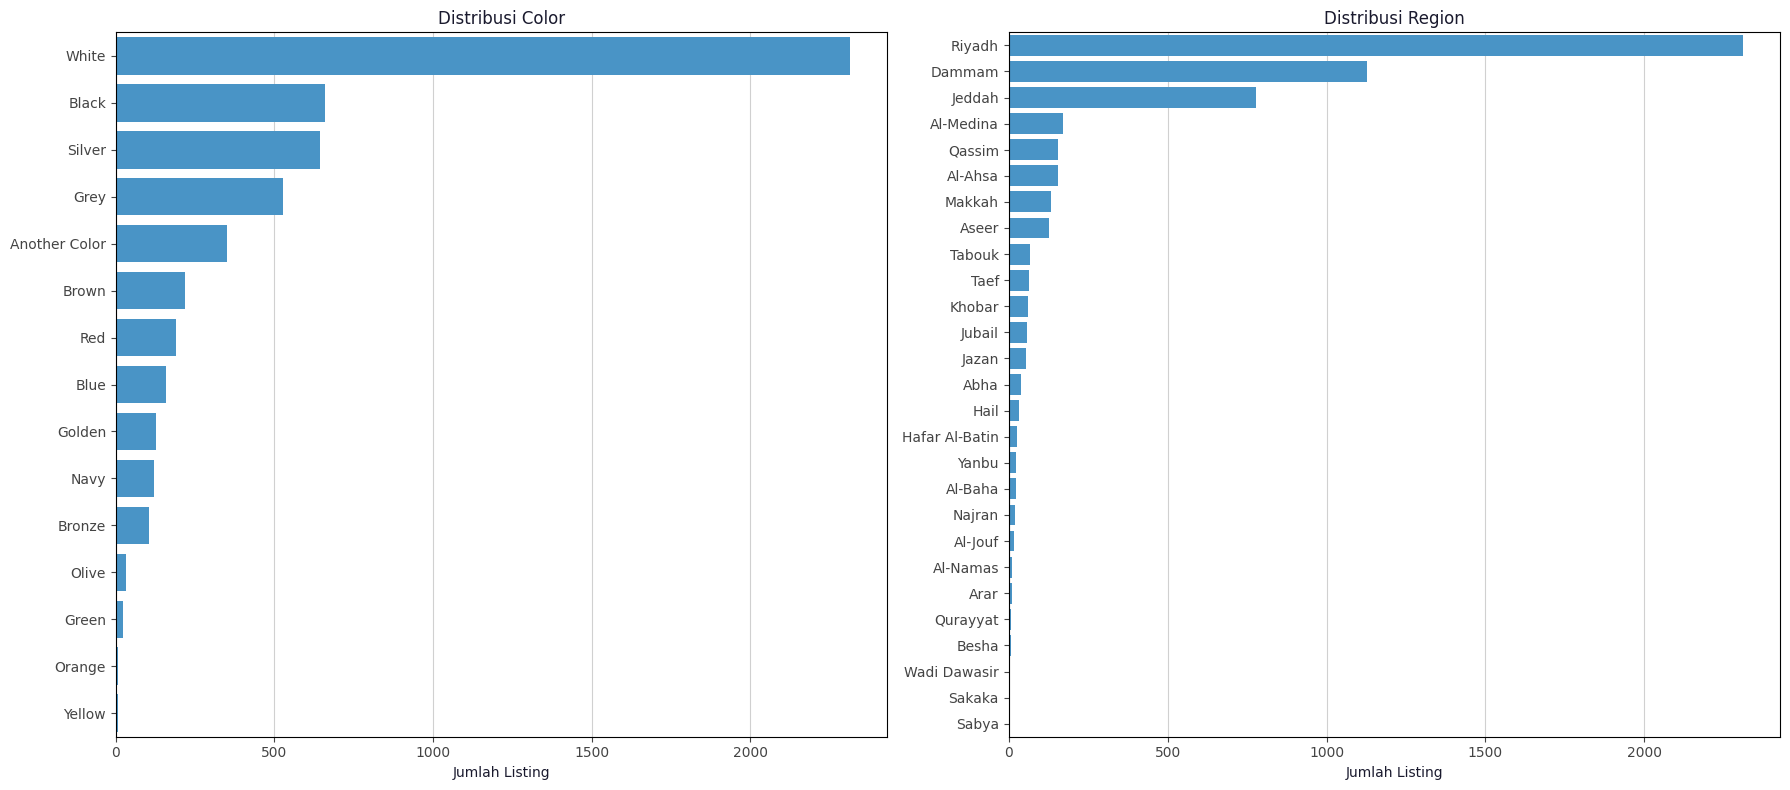

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, col in zip(axes, ['Color', 'Region']):
    sns.countplot(y=df[col], order=df[col].value_counts().index, color=BLUE, ax=ax)
    ax.set_title(f'Distribusi {col}')
    ax.set_xlabel('Jumlah Listing')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

Kolom `Color` didominasi oleh warna putih (42,2%), diikuti hitam (12,0%) dan silver (11,7%). Kolom `Region` juga terkonsentrasi di tiga kota besar, yaitu Riyadh (42,1%), Dammam (20,5%), dan Jeddah (14,2%), yang bersama-sama mencakup 76,8% listing. Sebanyak 14 dari 27 wilayah masing-masing memiliki proporsi kurang dari 1%.

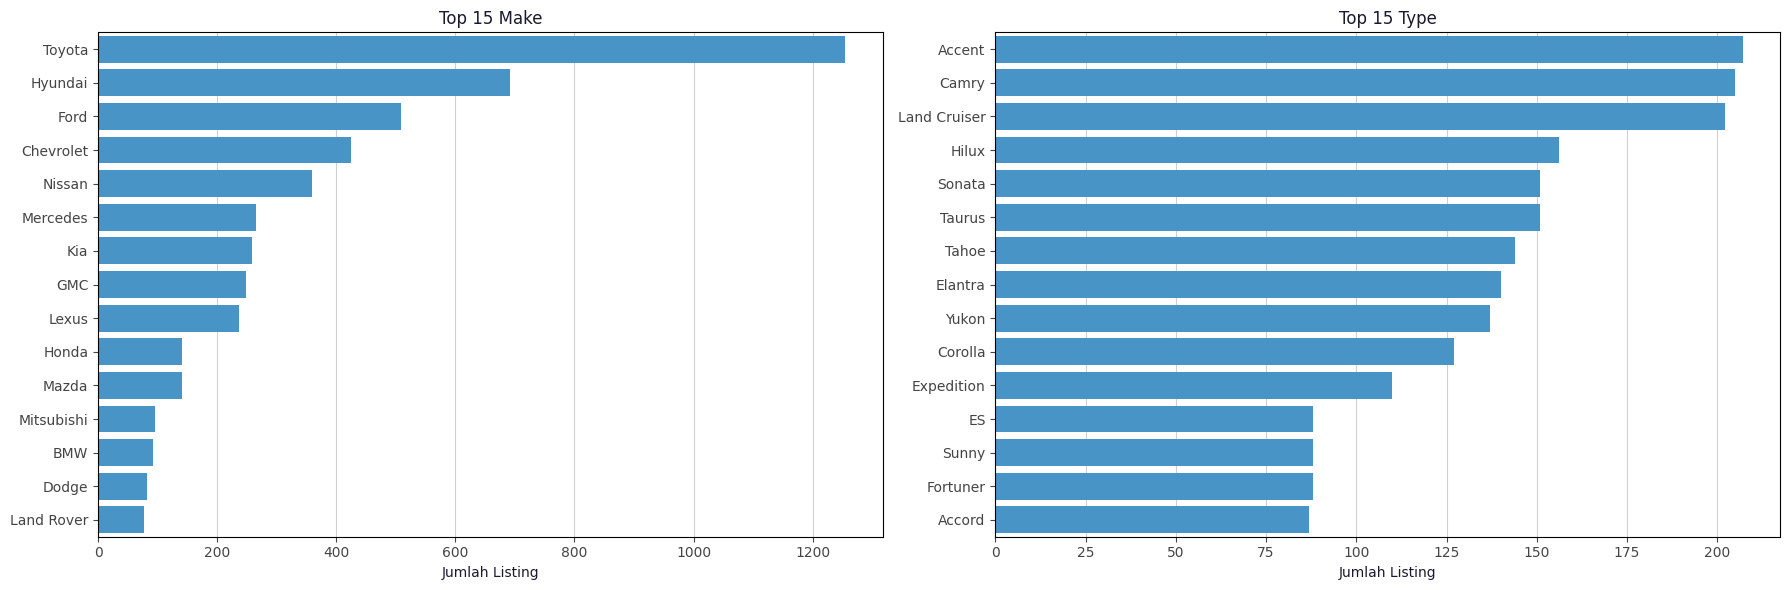

Make: 60 kategori | Top 15 mencakup 88.9% data | kategori < 10 listing: 23 | kategori dengan 1 listing: 9
Type: 385 kategori | Top 15 mencakup 37.9% data | kategori < 10 listing: 289 | kategori dengan 1 listing: 111


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, col in zip(axes, ['Make', 'Type']):
    top = df[col].value_counts().head(15)
    sns.barplot(x=top.values, y=top.index, color=BLUE, ax=ax)
    ax.set_title(f'Top 15 {col}')
    ax.set_xlabel('Jumlah Listing')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

for col in ['Make', 'Type']:
    vc = df[col].value_counts()
    print(f"{col}: {vc.size} kategori | Top 15 mencakup {vc.head(15).sum() / len(df):.1%} data | "
          f"kategori < 10 listing: {(vc < 10).sum()} | kategori dengan 1 listing: {(vc == 1).sum()}")

Kolom `Make` dan `Type` merupakan fitur dengan kardinalitas tinggi (jumlah kategori sangat banyak). Pada `Make`, terdapat 60 merek, tetapi lima merek teratas (Toyota, Hyundai, Ford, Chevrolet, dan Nissan) sudah mencakup 59,0% listing, dan 15 merek teratas mencakup 88,9%. Sementara itu, kolom `Type` jauh lebih tersebar. Dari 385 model, 15 model teratas hanya mencakup 37,9% listing, 289 model memiliki kurang dari 10 listing, dan 111 model hanya muncul satu kali. Banyaknya kategori dengan jumlah data yang sangat sedikit ini perlu diperhatikan saat encoding pada tahap modeling, karena model akan kesulitan mempelajari pola dari kategori yang hanya muncul sekali atau dua kali.

#### **1.1.4 Perbandingan Listing Negotiable dan Listing yang Mempunyai Harga**

Pada bagian Business Understanding, model diasumsikan dapat digunakan untuk memberikan estimasi harga pasar bagi listing Negotiable, dengan syarat karakteristik kendaraannya sebanding dengan listing yang mencantumkan harga. Bagian ini memvalidasi asumsi tersebut dengan membandingkan kedua kelompok listing dari sisi fitur numerik, merek, kelengkapan fitur, dan kelengkapan data.

In [54]:
df_nego = pd.read_csv('../data/processed/cars_negotiable.csv')

# Konversi Year ke Car_Age, sama seperti pada data harga tercantum
df_nego['Car_Age'] = (2021 - df_nego['Year']).clip(lower=0)
df_nego = df_nego.drop(columns='Year')

num_cols = ['Car_Age', 'Mileage', 'Engine_Size']
assert set(num_cols).issubset(df_nego.columns), 'Kolom numerik tidak lengkap di data Negotiable'

# Nilai kosong memang dibiarkan dari Data Preparation, ditampilkan sebagai informasi
display(pd.DataFrame({
    'Harga tercantum (%)': (df[num_cols].isna().mean() * 100).round(1),
    'Negotiable (%)': (df_nego[num_cols].isna().mean() * 100).round(1),
}))

df_cmp = pd.concat([
    df[num_cols + ['Make', 'Options']].assign(Status='Harga tercantum'),
    df_nego[num_cols + ['Make', 'Options']].assign(Status='Negotiable'),
], ignore_index=True)

# Ringkasan median per kelompok (nilai kosong otomatis diabaikan)
df_cmp.groupby('Status')[num_cols].median()

,Harga tercantum (%),Negotiable (%)
Car_Age,0.0,0.0
Mileage,7.1,17.7
Engine_Size,21.7,40.1


,Car_Age,Mileage,Engine_Size
Status,,,
Harga tercantum,5.0,109000.0,2.7
Negotiable,7.0,144790.5,3.0


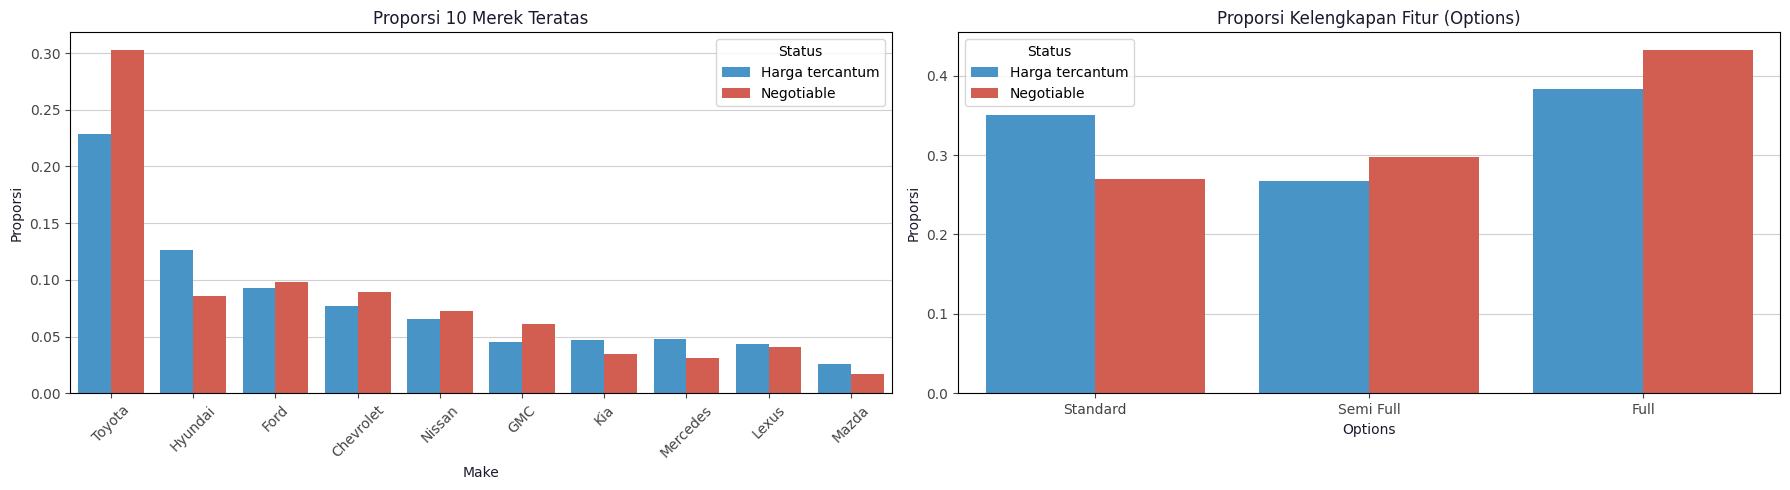

In [55]:
# Proporsi dihitung dari seluruh listing per kelompok, lalu difilter ke 10 merek teratas
top_make = df_cmp['Make'].value_counts().head(10).index

make_share = (df_cmp.groupby('Status')['Make'].value_counts(normalize=True)
                    .rename('Proporsi').reset_index())
make_share = make_share[make_share['Make'].isin(top_make)]

options_share = (df_cmp.groupby('Status')['Options'].value_counts(normalize=True)
                       .rename('Proporsi').reset_index())

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.barplot(data=make_share, x='Make', y='Proporsi', hue='Status',
            hue_order=['Harga tercantum', 'Negotiable'], palette=[BLUE, RED],
            order=top_make, ax=axes[0])
axes[0].set_title('Proporsi 10 Merek Teratas')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(data=options_share, x='Options', y='Proporsi', hue='Status',
            hue_order=['Harga tercantum', 'Negotiable'], palette=[BLUE, RED],
            order=['Standard', 'Semi Full', 'Full'], ax=axes[1])
axes[1].set_title('Proporsi Kelengkapan Fitur (Options)')

plt.tight_layout()
plt.show()

Untuk memastikan apakah perbedaan karakteristik antara kedua kelompok cukup besar, dilakukan uji Mann-Whitney U pada setiap fitur numerik. Uji ini dipilih karena distribusi fitur numerik tidak normal dan kedua kelompok saling independen. Hipotesis yang diuji untuk setiap fitur adalah sebagai berikut:

- H0: Distribusi fitur sama pada listing Negotiable dan listing berharga
- H1: Distribusi fitur berbeda pada kedua kelompok

Tingkat signifikansi yang digunakan adalah α = 0,05, dan besar perbedaan diukur menggunakan effect size rank-biserial correlation (r), dengan acuan 0,1 kecil, 0,3 sedang, dan 0,5 besar. Selain itu, diperiksa juga apakah merek dan model kendaraan pada listing Negotiable sudah tercakup dalam listing berharga, karena model hanya dapat mempelajari pola dari kategori yang ada pada data training.

In [56]:
# Uji perbedaan distribusi fitur numerik (Mann-Whitney U)
results = []
for col in num_cols:
    priced = df[col].dropna()
    nego = df_nego[col].dropna()
    u, p = stats.mannwhitneyu(priced, nego)
    results.append({'Fitur': col, 'p-value': p,
                    'Effect size (r)': round(abs(2 * u / (len(priced) * len(nego)) - 1), 3)})
display(pd.DataFrame(results))

# Cakupan kategori: apakah merek dan model di data Negotiable juga ada di data berharga
print(f"Merek Negotiable yang ada di data berharga : {df_nego['Make'].isin(df['Make']).mean():.1%}")
print(f"Model Negotiable yang ada di data berharga : {df_nego['Type'].isin(df['Type']).mean():.1%}")
print(f"Listing dengan model yang tidak dikenal    : {(~df_nego['Type'].isin(df['Type'])).sum()}")
print(f"Mobil berumur > 12 tahun : Harga tercantum {(df['Car_Age'] > 12).mean():.1%} | "
      f"Negotiable {(df_nego['Car_Age'] > 12).mean():.1%}")

,Fitur,p-value,Effect size (r)
0,Car_Age,1.071066e-70,0.244
1,Mileage,4.826648e-17,0.125
2,Engine_Size,7.199555e-09,0.099


Merek Negotiable yang ada di data berharga : 99.8%
Model Negotiable yang ada di data berharga : 97.9%
Listing dengan model yang tidak dikenal    : 54
Mobil berumur > 12 tahun : Harga tercantum 9.8% | Negotiable 21.7%


Hasil perbandingan menunjukkan bahwa asumsi pada bagian Business Understanding secara umum terpenuhi. Sebanyak 99,8% listing Negotiable memiliki merek dan 97,9% memiliki model kendaraan yang juga terdapat pada listing berharga, sehingga hampir seluruh listing Negotiable berasal dari jenis kendaraan yang sudah dikenali oleh model. Distribusi merek dan kelengkapan fitur pada kedua kelompok juga serupa, dengan Toyota, Hyundai, dan Ford sebagai merek terbanyak di keduanya.

Meskipun demikian, terdapat beberapa perbedaan. Listing Negotiable cenderung berisi mobil yang lebih tua, dengan median umur 7 tahun dibandingkan 5 tahun, dan proporsi mobil berumur lebih dari 12 tahun yang lebih dari dua kali lipat (21,7% dibandingkan 9,8%). Jarak tempuhnya juga lebih tinggi, dengan median 144.790 km dibandingkan 109.000 km. Perbedaan ini signifikan secara statistik, tetapi effect size-nya tergolong kecil hingga sangat kecil (r = 0,24 untuk umur, 0,13 untuk jarak tempuh, dan 0,10 untuk ukuran mesin), sehingga kedua kelompok masih dapat dianggap sebanding. Pola ini juga masuk akal secara bisnis. Harga mobil tua kemungkinan lebih sulit ditentukan karena kondisinya lebih bervariasi, sehingga penjual cenderung tidak mencantumkan harga. Bagi Syarah, hal ini juga berarti inspeksi kondisi mobil menjadi semakin penting sebelum estimasi model dijadikan penawaran beli.

Perbedaan lain terlihat pada kelengkapan data. Proporsi nilai kosong pada `Engine_Size` di listing Negotiable mencapai 40,1%, hampir dua kali lipat dibandingkan listing berharga (21,7%), begitu pula pada `Mileage` (17,7% dibandingkan 7,1%). Hal ini menunjukkan bahwa penjual yang tidak mencantumkan harga juga cenderung mengisi informasi kendaraan dengan kurang lengkap. Kedua perbedaan ini perlu diperhatikan saat menerapkan model pada listing Negotiable. Mobil berumur tua jumlahnya lebih sedikit pada data training, dan cukup banyak nilai fitur yang harus diisi melalui imputasi, sehingga estimasi harga untuk listing Negotiable berpotensi kurang akurat dibandingkan performa model pada data testing. Hal ini sebaiknya diperhatikan oleh tim pengadaan Syarah, misalnya dengan **menyajikan estimasi dalam bentuk rentang harga**, bukan satu angka pasti.

### **1.2 Faktor-Faktor yang Memengaruhi Harga**

#### **1.2.1 Pengaruh Umur, Jarak Tempuh, dan Ukuran Mesin terhadap Harga**

Bagian ini menguji hubungan antara setiap fitur numerik (`Car_Age`, `Mileage`, dan `Engine_Size`) dengan `Price`. Uji yang digunakan adalah korelasi Spearman, bukan Pearson, karena tiga alasan. Pertama, `Price` tidak berdistribusi normal, seperti yang terlihat dari skewness 3,74 pada bagian sebelumnya. Kedua, Spearman mengukur hubungan monoton, yaitu apakah nilai `Price` cenderung naik atau turun seiring kenaikan fitur, tanpa mengharuskan hubungannya berbentuk garis lurus. Ketiga, Spearman bekerja berdasarkan peringkat data, sehingga tidak mudah terpengaruh oleh nilai ekstrem seperti harga mobil mewah.

Hipotesis yang diuji untuk setiap fitur adalah sebagai berikut:
- H0: Tidak terdapat hubungan monoton antara fitur dan `Price` (ρ = 0)
- H1: Terdapat hubungan monoton antara fitur dan `Price` (ρ ≠ 0)

Tingkat signifikansi yang digunakan adalah α = 0,05. Nilai kosong pada `Mileage` dan `Engine_Size` diabaikan dalam perhitungan.

Kekuatan hubungan dinilai dari nilai |ρ| menggunakan acuan Evans (1996): 0,00–0,19 sangat lemah, 0,20–0,39 lemah, 0,40–0,59 sedang, 0,60–0,79 kuat, dan 0,80–1,00 sangat kuat.

Referensi:

- Evans, J. D. (1996). Straightforward Statistics for the Behavioral Sciences. Brooks/Cole Publishing.

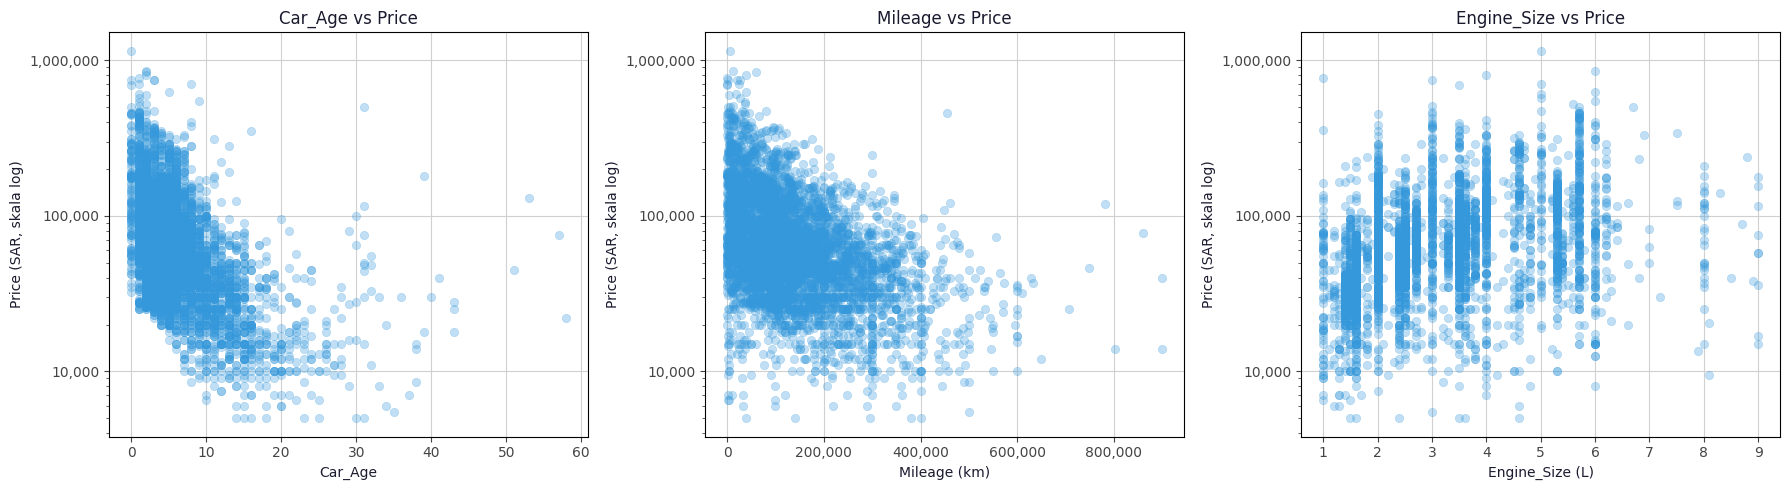

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, num_cols):
    sns.scatterplot(x=df[col], y=df['Price'], alpha=0.3, color=BLUE, edgecolor=None, ax=ax)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(sar_fmt)
    ax.set_title(f'{col} vs Price')
    ax.set_ylabel('Price (SAR, skala log)')

axes[1].xaxis.set_major_formatter(sar_fmt)
axes[1].set_xlabel('Mileage (km)')
axes[2].set_xlabel('Engine_Size (L)')

plt.tight_layout()
plt.show()

Pada scatter plot, sumbu `Price` ditampilkan dalam skala logaritmik agar pola pada rentang harga rendah hingga menengah tetap terlihat, mengingat distribusi `Price` yang sangat condong ke kanan. Skala ini hanya mengubah tampilan grafik dan tidak memengaruhi hasil uji Spearman, karena Spearman bekerja berdasarkan peringkat data.

In [58]:
results = []
for col in num_cols:
    data = df[[col, 'Price']].dropna()
    rho, p = stats.spearmanr(data[col], data['Price'])
    results.append({
        'Fitur': col,
        'n': len(data),
        'Spearman ρ': round(rho, 3),
        'p-value': p,
        'Keputusan': 'Tolak H0' if p < 0.05 else 'Gagal tolak H0',
    })

pd.DataFrame(results)

,Fitur,n,Spearman ρ,p-value,Keputusan
0,Car_Age,5487,-0.475,2.935916e-306,Tolak H0
1,Mileage,5100,-0.424,1.056778e-221,Tolak H0
2,Engine_Size,4298,0.454,3.819123e-218,Tolak H0


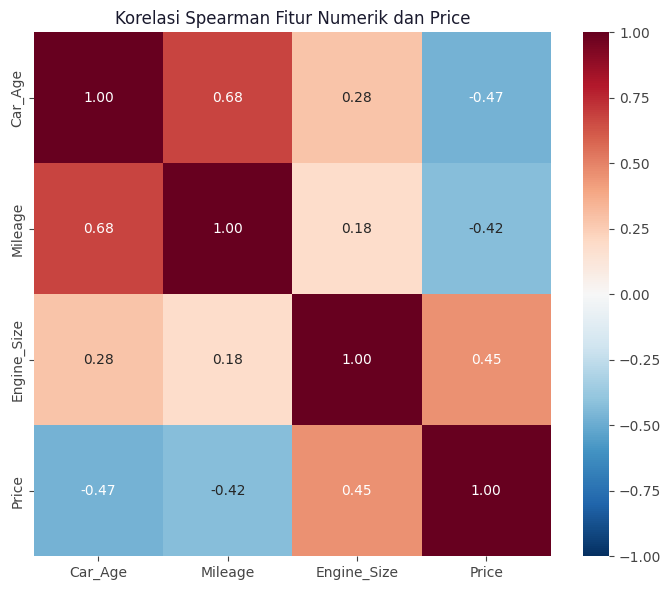

In [59]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(df[num_cols + ['Price']].corr(method='spearman'),
            annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)
ax.set_title('Korelasi Spearman Fitur Numerik dan Price')

plt.tight_layout()
plt.show()

Ketiga fitur numerik memiliki p-value jauh di bawah 0,05, sehingga H0 ditolak dan dapat disimpulkan bahwa ketiganya memiliki hubungan monoton yang signifikan dengan `Price`. Kekuatan hubungannya berada pada tingkat sedang, dengan nilai ρ berkisar 0,42–0,48.

`Car_Age` memiliki hubungan terkuat dengan arah negatif (ρ = −0,475), artinya semakin tua umur mobil, harganya cenderung semakin rendah. Scatter plot juga menunjukkan bahwa penurunan harga paling tajam terjadi pada beberapa tahun pertama, lalu melandai setelah mobil berumur lebih dari 15 tahun. Menariknya, beberapa mobil berumur lebih dari 25 tahun justru memiliki harga yang relatif tinggi, kemungkinan karena nilai koleksinya sebagai mobil klasik. `Mileage` juga berhubungan negatif dengan `Price` (ρ = −0,424), sesuai dengan logika bahwa mobil yang lebih sering dipakai cenderung lebih murah. Sebaliknya, `Engine_Size` berhubungan positif (ρ = 0,454), karena mobil bermesin besar umumnya merupakan SUV, truk, atau mobil mewah dengan harga lebih tinggi. Namun, sebaran harga pada setiap ukuran mesin sangat lebar, yang menunjukkan bahwa ukuran mesin saja tidak cukup untuk menentukan harga.

Heatmap juga menunjukkan bahwa `Car_Age` dan `Mileage` saling berkorelasi kuat (ρ = 0,68). Hal ini wajar karena mobil yang lebih tua umumnya sudah menempuh jarak lebih jauh. Meskipun demikian, keduanya tetap dipertahankan karena membawa informasi yang berbeda. Dua mobil dengan umur yang sama bisa memiliki jarak tempuh yang sangat berbeda, dan perbedaan ini dapat memengaruhi harga. Korelasi antar fitur ini akan diperiksa lebih lanjut menggunakan VIF pada bagian 1.3.3, untuk memastikan tidak terjadi multikolinearitas yang dapat memengaruhi model linear.

#### **1.2.2 Pengaruh Merek, Model, dan Karakteristik Lainnya terhadap Harga**

Bagian ini menguji apakah terdapat perbedaan `Price` antar kategori pada setiap fitur kategorikal. Karena `Price` tidak berdistribusi normal, uji yang digunakan adalah uji non-parametrik yang membandingkan peringkat data, bukan rata-rata. Untuk fitur dengan dua kategori (`Gear_Type`), digunakan uji Mann-Whitney U. Untuk fitur dengan lebih dari dua kategori, digunakan uji Kruskal-Wallis.

Hipotesis yang diuji untuk setiap fitur adalah sebagai berikut:
- H0: Distribusi `Price` sama pada seluruh kategori
- H1: Terdapat minimal satu kategori dengan distribusi `Price` yang berbeda

Tingkat signifikansi yang digunakan adalah α = 0,05. Dengan jumlah data yang besar (sekitar 5.500 listing), perbedaan yang sangat kecil pun dapat menghasilkan p-value yang signifikan. Oleh karena itu, selain p-value, dihitung juga effect size untuk mengukur seberapa besar perbedaan tersebut. Effect size yang digunakan adalah rank-biserial correlation (r) untuk Mann-Whitney U, dengan acuan 0,1 kecil, 0,3 sedang, dan 0,5 besar (Cohen, 1988). Untuk Kruskal-Wallis digunakan epsilon-squared (ε²), dengan acuan 0,01 kecil, 0,08 sedang, dan 0,26 besar (Mangiafico, 2016). Acuan ini merupakan panduan umum, sehingga digunakan untuk membandingkan kekuatan relatif antar fitur, bukan sebagai batas mutlak.

Referensi:

- Cohen, J. (1988). Statistical Power Analysis for the Behavioral Sciences (2nd ed.). Lawrence Erlbaum Associates.
- Mangiafico, S. S. (2016). Summary and Analysis of Extension Program Evaluation in R. Rutgers Cooperative Extension. https://rcompanion.org/handbook/F_08.html

Untuk fitur dengan kardinalitas rendah (`Origin`, `Options`, `Fuel_Type`, dan `Gear_Type`), hubungan dengan `Price` divisualisasikan menggunakan boxplot. Boxplot dipilih karena jumlah kategorinya sedikit, sehingga median, sebaran harga, dan nilai ekstrem pada setiap kategori masih dapat dibandingkan dengan jelas dalam satu grafik.

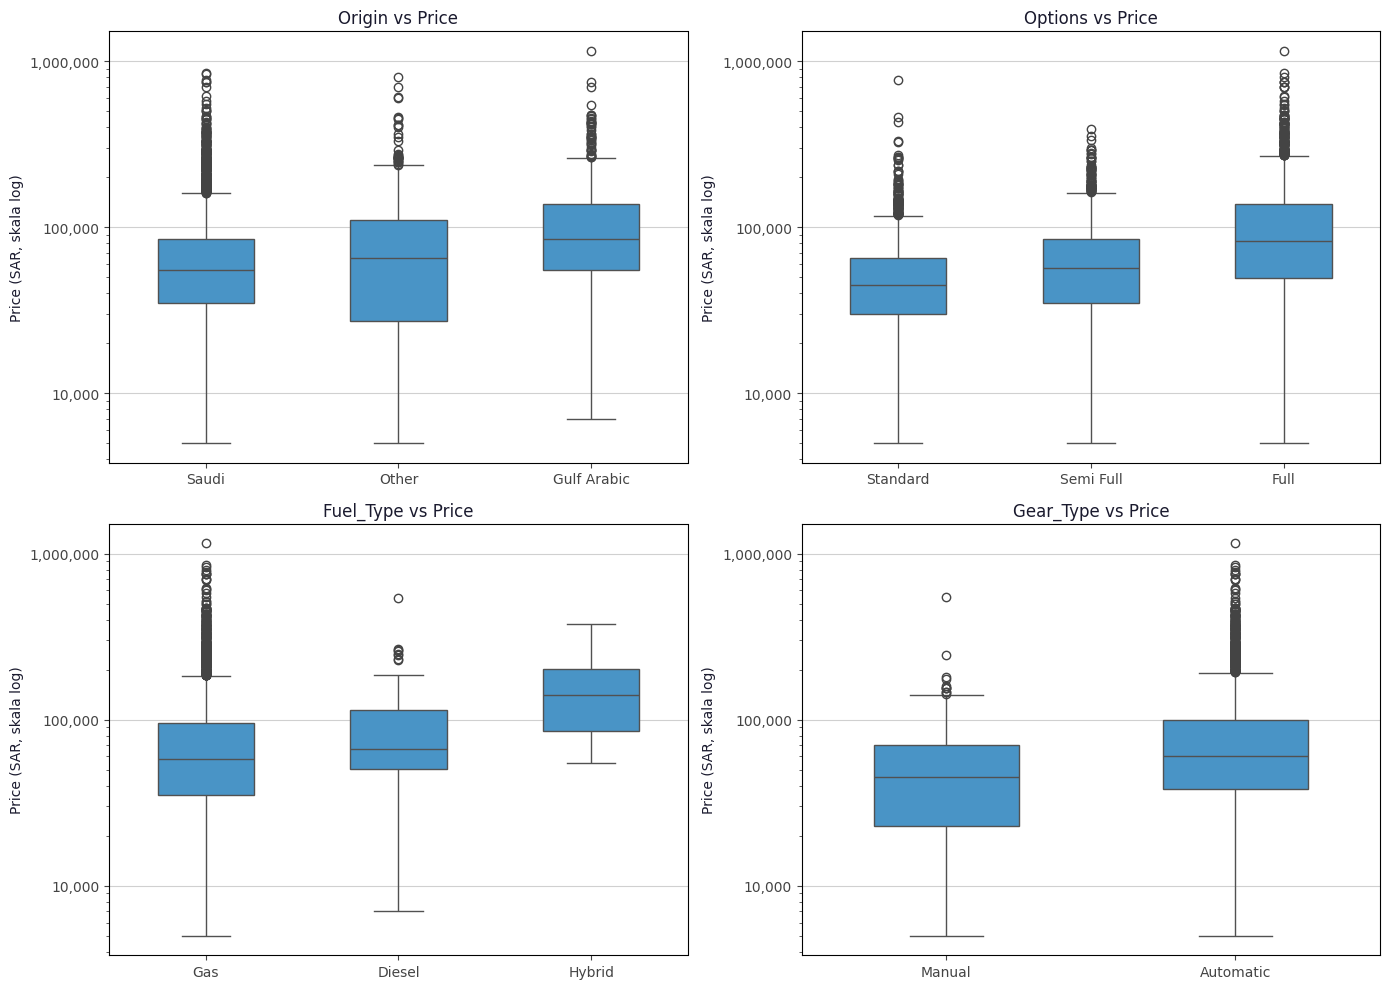

In [60]:
low_card_cols = ['Origin', 'Options', 'Fuel_Type', 'Gear_Type']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, low_card_cols):
    order = df.groupby(col)['Price'].median().sort_values().index
    sns.boxplot(x=df[col], y=df['Price'], order=order, color=BLUE, width=0.5, ax=ax,
                flierprops={'markerfacecolor': 'none', 'markeredgecolor': '#444444'})
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(sar_fmt)
    ax.set_title(f'{col} vs Price')
    ax.set_xlabel('')
    ax.set_ylabel('Price (SAR, skala log)')

plt.tight_layout()
plt.show()

In [61]:
def kruskal_test(df, col, target='Price'):
    """Uji Kruskal-Wallis beserta effect size epsilon-squared.

    Args:
        df (pd.DataFrame): Data input.
        col (str): Nama fitur kategorikal.
        target (str): Nama kolom target.

    Returns:
        dict: Hasil uji untuk satu fitur.
    """
    data = df[[col, target]].dropna()
    groups = [g.values for _, g in data.groupby(col)[target]]
    h, p = stats.kruskal(*groups)
    n, k = len(data), len(groups)
    return {'Fitur': col, 'Uji': 'Kruskal-Wallis', 'Statistik': round(h, 1), 'p-value': p,
            'Effect size': round((h - k + 1) / (n - k), 3), 'Jenis effect size': 'ε²'}


def mannwhitney_test(df, col, target='Price'):
    """Uji Mann-Whitney U beserta effect size rank-biserial correlation.

    Args:
        df (pd.DataFrame): Data input.
        col (str): Nama fitur kategorikal dengan dua kategori.
        target (str): Nama kolom target.

    Returns:
        dict: Hasil uji untuk satu fitur.
    """
    data = df[[col, target]].dropna()
    group_a, group_b = [g.values for _, g in data.groupby(col)[target]]
    u, p = stats.mannwhitneyu(group_a, group_b)
    r_rb = 2 * u / (len(group_a) * len(group_b)) - 1
    return {'Fitur': col, 'Uji': 'Mann-Whitney U', 'Statistik': round(u, 1), 'p-value': p,
            'Effect size': round(abs(r_rb), 3), 'Jenis effect size': 'r'}


results = [kruskal_test(df, col) for col in ['Origin', 'Options', 'Fuel_Type']]
results.append(mannwhitney_test(df, 'Gear_Type'))

results = pd.DataFrame(results)
results['Keputusan'] = np.where(results['p-value'] < 0.05, 'Tolak H0', 'Gagal tolak H0')
results

,Fitur,Uji,Statistik,p-value,Effect size,Jenis effect size,Keputusan
0,Origin,Kruskal-Wallis,207.7,7.893869e-46,0.038,ε²,Tolak H0
1,Options,Kruskal-Wallis,684.6,2.235871e-149,0.125,ε²,Tolak H0
2,Fuel_Type,Kruskal-Wallis,23.6,7.471688e-06,0.004,ε²,Tolak H0
3,Gear_Type,Mann-Whitney U,1840509.5,1.658990e-29,0.284,r,Tolak H0


In [62]:
# Median Price per kategori
for col in low_card_cols:
    print(df.groupby(col)['Price'].agg(['count', 'median']).sort_values('median'), '\n')

             count   median
Origin                     
Saudi         4114  55000.0
Other          631  65000.0
Gulf Arabic    716  85000.0 

           count   median
Options                  
Standard    1906  45000.0
Semi Full   1455  57000.0
Full        2087  82500.0 

           count    median
Fuel_Type                 
Gas         5378   58000.0
Diesel        98   66500.0
Hybrid        11  140000.0 

           count   median
Gear_Type                
Manual       587  45000.0
Automatic   4882  60000.0 



Keempat fitur memiliki p-value di bawah 0,05, sehingga H0 ditolak dan dapat disimpulkan bahwa terdapat perbedaan `Price` yang signifikan antar kategori pada setiap fitur. Namun, effect size menunjukkan bahwa besar perbedaannya sangat bervariasi.

`Options` memiliki effect size terbesar (ε² = 0,125, tergolong sedang), dengan pola harga yang naik secara berurutan dari Standard (median 45.000 SAR), Semi Full (57.000 SAR), hingga Full (82.500 SAR). Pola ini sesuai dengan sifat `Options` yang ordinal, yaitu semakin lengkap fitur kendaraan, semakin tinggi harganya. `Gear_Type` menunjukkan perbedaan yang kecil (r = 0,284), dengan median harga mobil otomatis (60.000 SAR) lebih tinggi dibandingkan mobil manual (45.000 SAR). `Origin` juga memiliki perbedaan yang kecil (ε² = 0,038), dengan mobil asal Gulf Arabic memiliki median tertinggi (85.000 SAR), diikuti Other (65.000 SAR) dan Saudi (55.000 SAR).

`Fuel_Type` memiliki effect size yang sangat kecil (ε² = 0,004), meskipun hasil ujinya signifikan. Median harga mobil Hybrid memang jauh lebih tinggi (140.000 SAR), tetapi kategori ini hanya berisi 11 listing, sementara 98% listing merupakan mobil berbahan bakar bensin. Akibatnya, `Fuel_Type` hampir tidak membedakan harga untuk sebagian besar data, sehingga kontribusinya terhadap model kemungkinan kecil.

Pengujian selanjutnya dilakukan pada `Color` dan `Region` menggunakan uji Kruskal-Wallis, dengan hipotesis dan tingkat signifikansi yang sama seperti pengujian sebelumnya. Karena kedua fitur ini memiliki jumlah kategori yang lebih banyak, visualisasi menggunakan bar chart median harga per kategori, karena boxplot dengan banyak kategori akan sulit dibaca. Jumlah listing (n) ditampilkan pada setiap bar, karena beberapa kategori hanya berisi sedikit listing, sehingga median harganya kurang dapat diandalkan.

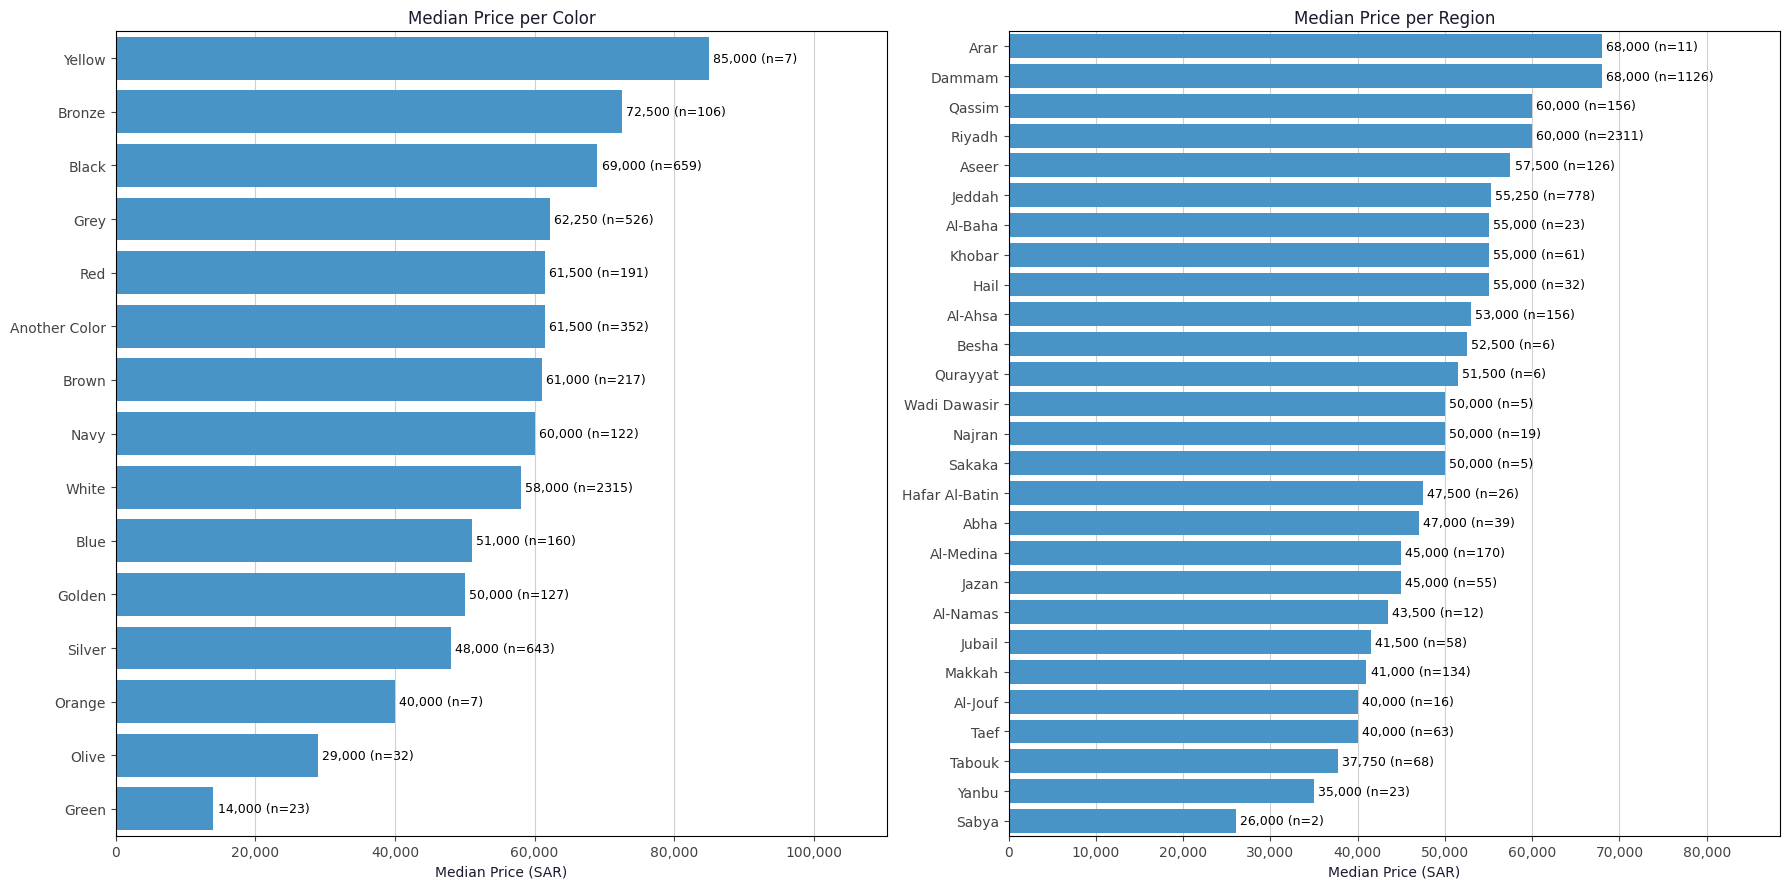

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(18, 9))

for ax, col in zip(axes, ['Color', 'Region']):
    summary = (df.groupby(col)['Price']
                 .agg(['median', 'count'])
                 .sort_values('median', ascending=False))
    sns.barplot(x=summary['median'], y=summary.index, color=BLUE, ax=ax)
    ax.bar_label(ax.containers[0],
                 labels=[f"{m:,.0f} (n={n})" for m, n in zip(summary['median'], summary['count'])],
                 padding=3, fontsize=9)
    ax.xaxis.set_major_formatter(sar_fmt)
    ax.set_title(f'Median Price per {col}')
    ax.set_xlabel('Median Price (SAR)')
    ax.set_ylabel('')
    ax.set_xlim(0, summary['median'].max() * 1.3)  # ruang untuk label

plt.tight_layout()
plt.show()

In [64]:
results = pd.DataFrame([kruskal_test(df, col) for col in ['Color', 'Region']])
results['Keputusan'] = np.where(results['p-value'] < 0.05, 'Tolak H0', 'Gagal tolak H0')
results

,Fitur,Uji,Statistik,p-value,Effect size,Jenis effect size,Keputusan
0,Color,Kruskal-Wallis,144.1,1.077439e-23,0.024,ε²,Tolak H0
1,Region,Kruskal-Wallis,171.1,2.560184e-23,0.027,ε²,Tolak H0


In [65]:
for col in ['Color', 'Region']:
    print(df.groupby(col)['Price'].agg(['count', 'median']).sort_values('median'), '\n')

               count   median
Color                        
Green             23  14000.0
Olive             32  29000.0
Orange             7  40000.0
Silver           643  48000.0
Golden           127  50000.0
Blue             160  51000.0
White           2315  58000.0
Navy             122  60000.0
Brown            217  61000.0
Red              191  61500.0
Another Color    352  61500.0
Grey             526  62250.0
Black            659  69000.0
Bronze           106  72500.0
Yellow             7  85000.0 

                count   median
Region                        
Sabya               2  26000.0
Yanbu              23  35000.0
Tabouk             68  37750.0
Al-Jouf            16  40000.0
Taef               63  40000.0
Makkah            134  41000.0
Jubail             58  41500.0
Al-Namas           12  43500.0
Jazan              55  45000.0
Al-Medina         170  45000.0
Abha               39  47000.0
Hafar Al-Batin     26  47500.0
Najran             19  50000.0
Sakaka              5  

In [66]:
color_age = df.groupby('Color').agg(
    count=('Price', 'size'),
    median_price=('Price', 'median'),
    median_age=('Car_Age', 'median'),
).sort_values('median_price')

color_age

,count,median_price,median_age
Color,,,
Green,23,14000.0,19.0
Olive,32,29000.0,11.0
Orange,7,40000.0,8.0
Silver,643,48000.0,5.0
Golden,127,50000.0,8.0
Blue,160,51000.0,6.0
White,2315,58000.0,5.0
Navy,122,60000.0,5.0
Brown,217,61000.0,5.0


`Color` dan `Region` sama-sama memiliki p-value di bawah 0,05, sehingga H0 ditolak dan dapat disimpulkan bahwa terdapat perbedaan `Price` yang signifikan antar kategori. Namun, effect size keduanya tergolong kecil (ε² = 0,024 untuk `Color` dan 0,027 untuk `Region`), sehingga perbedaan harga yang dijelaskan oleh kedua fitur ini relatif terbatas.

Pada `Color`, sebagian besar warna memiliki median harga yang berdekatan, yaitu di kisaran 48.000–72.500 SAR. Perbedaan yang mencolok hanya terlihat pada warna hijau (median 14.000 SAR) dan olive (29.000 SAR). Namun, rendahnya harga ini kemungkinan besar bukan disebabkan oleh warnanya, melainkan oleh umur mobil. Median umur mobil berwarna hijau adalah 19 tahun dan olive 11 tahun, jauh di atas median umur keseluruhan data yang hanya 5 tahun. Selain itu, warna dengan median tertinggi (Yellow, 85.000 SAR) dan Orange hanya berisi 7 listing, sehingga median harganya kurang dapat diandalkan.

Pada `Region`, kota-kota besar seperti Dammam dan Riyadh memiliki median harga tertinggi, masing-masing 68.000 dan 60.000 SAR. Sebaliknya, beberapa wilayah seperti Yanbu, Tabouk, dan Makkah memiliki median di kisaran 35.000–41.000 SAR. Perbedaan ini kemungkinan mencerminkan jenis mobil yang dijual di masing-masing wilayah, bukan lokasi itu sendiri. Sebanyak 5 dari 27 wilayah memiliki kurang dari 10 listing, sehingga median harga pada wilayah tersebut juga kurang dapat diandalkan.

Pengujian selanjutnya dilakukan pada `Make` dan `Type` menggunakan uji Kruskal-Wallis, dengan hipotesis dan tingkat signifikansi yang sama seperti pengujian sebelumnya. Karena kedua fitur ini memiliki kardinalitas tinggi, visualisasi hanya menampilkan 15 kategori dengan jumlah listing terbanyak dalam bentuk bar chart median harga, dengan alasan yang sama seperti pada `Color` dan `Region`. Selain itu, banyaknya kategori dengan jumlah listing yang sangat sedikit dapat membuat nilai effect size menjadi lebih besar dari yang seharusnya. Oleh karena itu, pengujian juga diulang hanya pada kategori yang memiliki minimal 10 listing, untuk memastikan hasilnya tetap konsisten.

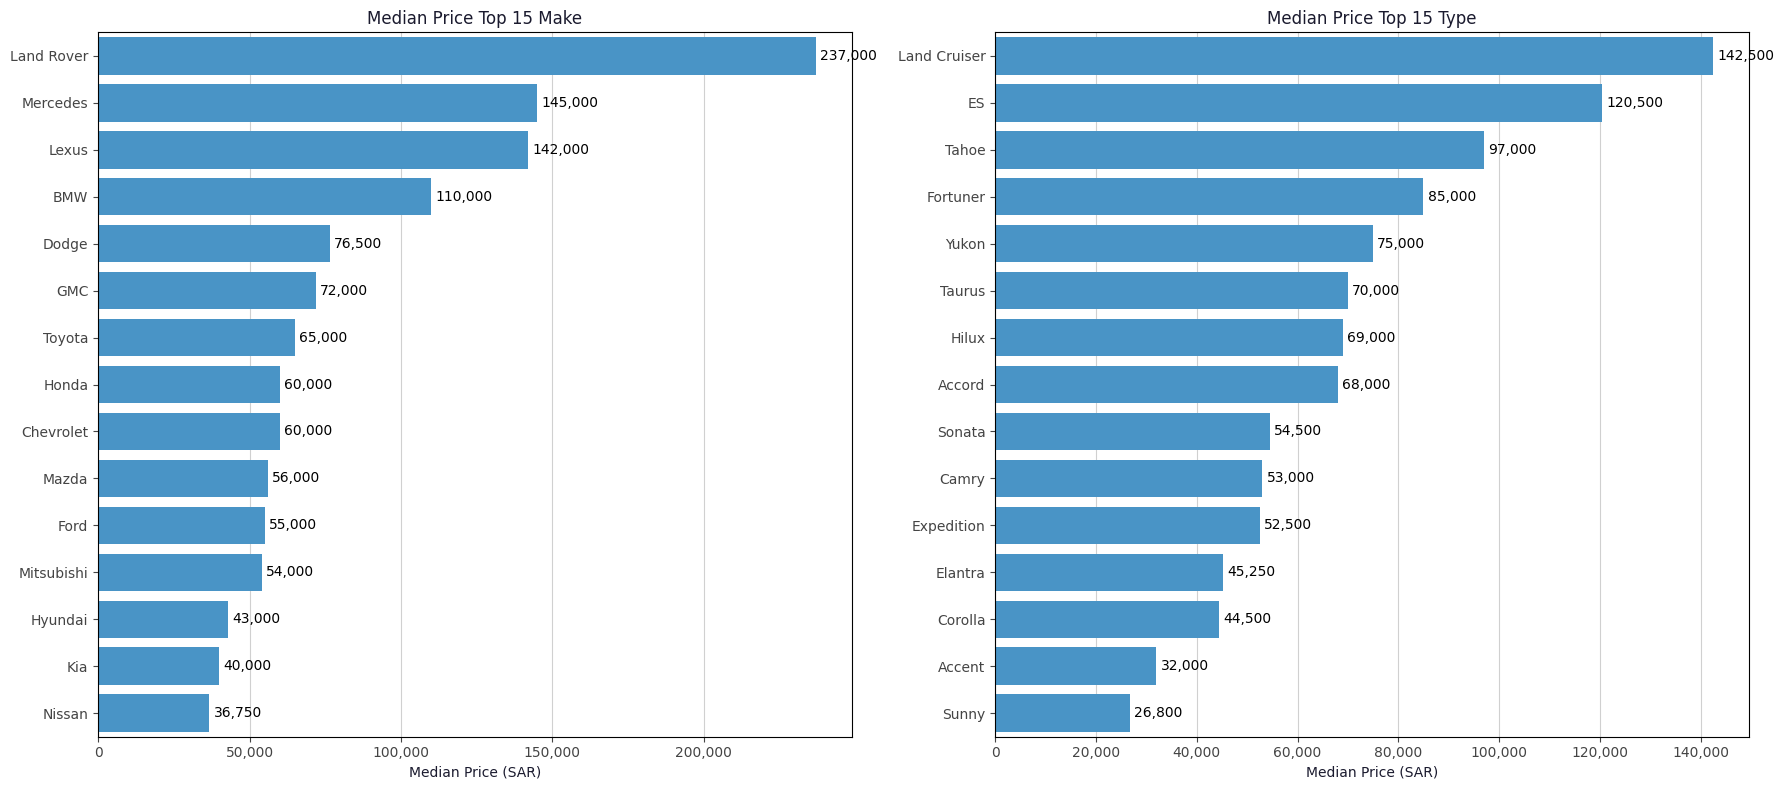

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for ax, col in zip(axes, ['Make', 'Type']):
    top = df[col].value_counts().head(15).index
    median_price = (df[df[col].isin(top)]
                    .groupby(col)['Price'].median()
                    .sort_values(ascending=False))
    sns.barplot(x=median_price.values, y=median_price.index, color=BLUE, ax=ax)
    ax.bar_label(ax.containers[0], labels=[f'{v:,.0f}' for v in median_price.values], padding=3)
    ax.xaxis.set_major_formatter(sar_fmt)
    ax.set_title(f'Median Price Top 15 {col}')
    ax.set_xlabel('Median Price (SAR)')
    ax.set_ylabel('')

plt.tight_layout()
plt.show()

In [68]:
results = []
for col in ['Make', 'Type']:
    # Semua kategori
    res_all = kruskal_test(df, col)
    res_all['Data'] = 'Semua kategori'
    res_all['n_kategori'] = df[col].nunique()
    results.append(res_all)

    # Hanya kategori dengan minimal 10 listing
    vc = df[col].value_counts()
    df_min10 = df[df[col].isin(vc[vc >= 10].index)]
    res_min10 = kruskal_test(df_min10, col)
    res_min10['Data'] = 'Kategori ≥ 10 listing'
    res_min10['n_kategori'] = df_min10[col].nunique()
    results.append(res_min10)

results = pd.DataFrame(results)
results['Keputusan'] = np.where(results['p-value'] < 0.05, 'Tolak H0', 'Gagal tolak H0')
results[['Fitur', 'Data', 'n_kategori', 'Statistik', 'p-value', 'Effect size', 'Keputusan']]

,Fitur,Data,n_kategori,Statistik,p-value,Effect size,Keputusan
0,Make,Semua kategori,60,1445.5,2.446589e-263,0.255,Tolak H0
1,Make,Kategori ≥ 10 listing,37,1376.3,6.780733e-266,0.249,Tolak H0
2,Type,Semua kategori,385,3024.3,0.000000e+00,0.518,Tolak H0
3,Type,Kategori ≥ 10 listing,96,2242.3,0.000000e+00,0.472,Tolak H0


In [69]:
top_type = df['Type'].value_counts().head(15).index

(df[df['Type'].isin(top_type)]
   .groupby(['Make', 'Type'])
   .agg(count=('Price', 'size'), median_price=('Price', 'median'), median_age=('Car_Age', 'median'))
   .sort_values('median_price'))

,,count,median_price,median_age
Make,Type,,,
Nissan,Sunny,88,26800.0,3.0
Hyundai,Accent,207,32000.0,3.0
Toyota,Corolla,127,44500.0,4.0
Hyundai,Elantra,140,45250.0,3.0
Ford,Expedition,110,52500.0,7.0
Toyota,Camry,205,53000.0,5.0
Hyundai,Sonata,151,54500.0,4.0
Honda,Accord,87,68000.0,5.0
Toyota,Hilux,156,69000.0,5.0


`Make` dan `Type` sama-sama memiliki p-value jauh di bawah 0,05, sehingga H0 ditolak. Berbeda dengan fitur kategorikal lainnya, effect size kedua fitur ini jauh lebih besar. `Make` memiliki ε² = 0,255 (tergolong sedang, mendekati batas besar), sedangkan `Type` memiliki ε² = 0,518, tertinggi di antara seluruh fitur kategorikal. Ketika pengujian diulang hanya pada kategori dengan minimal 10 listing, nilai effect size tidak banyak berubah (0,249 untuk `Make` dan 0,472 untuk `Type`). Hal ini menunjukkan bahwa besarnya pengaruh kedua fitur bukan disebabkan oleh banyaknya kategori dengan jumlah listing yang sedikit.

Pada `Make`, terlihat pengelompokan harga berdasarkan segmen merek. Merek-merek ekonomis seperti Nissan, Kia, dan Hyundai memiliki median harga di kisaran 36.750–43.000 SAR. Sebaliknya, merek premium seperti Lexus, Mercedes, dan Land Rover memiliki median harga 142.000–237.000 SAR, atau sekitar 3–6 kali lipat lebih tinggi.

Pada `Type`, perbedaan harga antar model bahkan lebih besar. Sebagai contoh, Nissan Sunny memiliki median harga 26.800 SAR, sedangkan Toyota Land Cruiser mencapai 142.500 SAR. Perbedaan ini tidak dapat dijelaskan oleh umur mobil, karena median umur keduanya berdekatan, yaitu 3 dan 6 tahun. Hal ini menunjukkan bahwa model kendaraan merupakan faktor yang sangat menentukan harga, karena model sudah mencerminkan segmen, ukuran, dan kelas kendaraan sekaligus.

Meskipun `Type` merupakan fitur paling informatif, fitur ini juga memiliki kardinalitas tertinggi (385 kategori) dengan banyak kategori yang hanya berisi sedikit listing. Oleh karena itu, pemilihan metode encoding untuk `Type` pada tahap modeling perlu dilakukan dengan hati-hati, agar informasi dari fitur ini dapat dimanfaatkan tanpa membuat model overfitting pada kategori yang jarang muncul.

### **1.3 Pengaruh Gabungan Antar Faktor (Multivariat)**

#### **1.3.1 Perbedaan Penurunan Harga Mobil Premium dan Non-Premium**

Hasil pada bagian 1.2 menunjukkan bahwa `Car_Age` merupakan fitur numerik dengan hubungan terkuat terhadap `Price`, sedangkan `Make` merupakan salah satu fitur kategorikal dengan effect size terbesar. Namun, pengujian tersebut hanya melihat hubungan setiap fitur dengan `Price` secara terpisah, sehingga tidak dapat menunjukkan apakah kedua fitur ini saling berinteraksi. Bagian ini memeriksa apakah kecepatan penurunan harga seiring bertambahnya umur mobil berbeda antara merek premium dan non-premium.

Merek dikelompokkan menjadi dua segmen berdasarkan posisinya di pasar otomotif, bukan berdasarkan harga di dataset, agar pengelompokan tidak bergantung pada variabel target. Segmen Premium mengacu pada klasifikasi Kelley Blue Book [2], yang membagi merek mobil mewah menjadi kelompok luxury (seperti Mercedes, BMW, Audi, Lexus, dan Land Rover) dan ultra-luxury (seperti Rolls-Royce, Bentley, Ferrari, dan Aston Martin). Kedua kelompok ini digabung menjadi satu segmen Premium, sedangkan merek lainnya masuk ke segmen Non-Premium. Pengelompokan ini juga sejalan dengan daftar mobil mewah di Arab Saudi menurut Syarah [1], yang mencakup Mercedes, BMW, Audi, Lexus, Genesis, Porsche, dan Cadillac. `Car_Age` juga dikelompokkan ke dalam lima kelompok umur (0–2, 3–5, 6–8, 9–12, dan lebih dari 12 tahun) agar pola penurunan harga lebih mudah dibandingkan.

[1] Syarah, *Top 10 Luxury Cars in Saudi Arabia*, https://syarah.com/carsguide/en/top-10-luxury-cars-saudi-arabia-2025/

[2] Kelley Blue Book, *Luxury Car Logos: See What They Mean*, https://www.kbb.com/car-advice/luxury-car-logos

In [70]:
# Merek premium berdasarkan klasifikasi luxury dan ultra-luxury Kelley Blue Book [2]
PREMIUM_MAKES = ['Aston Martin', 'Audi', 'Bentley', 'BMW', 'Cadillac', 'Ferrari', 'Genesis',
                 'INFINITI', 'Jaguar', 'Land Rover', 'Lexus', 'Lincoln', 'Maserati', 'Mercedes',
                 'Porsche', 'Rolls-Royce', 'Volvo']

df_mv = df.copy()
df_mv['Segment'] = np.where(df_mv['Make'].isin(PREMIUM_MAKES), 'Premium', 'Non-Premium')
df_mv['Age_Group'] = pd.cut(df_mv['Car_Age'], bins=[-1, 2, 5, 8, 12, df_mv['Car_Age'].max()],
                            labels=['0-2', '3-5', '6-8', '9-12', '>12'])

# Validasi: semua listing masuk ke salah satu kelompok umur
assert df_mv['Age_Group'].notna().all()

df_mv.groupby(['Age_Group', 'Segment'], observed=True).size().unstack()

Segment,Non-Premium,Premium
Age_Group,,
0-2,815,180
3-5,1801,321
6-8,1040,204
9-12,512,77
>12,430,107


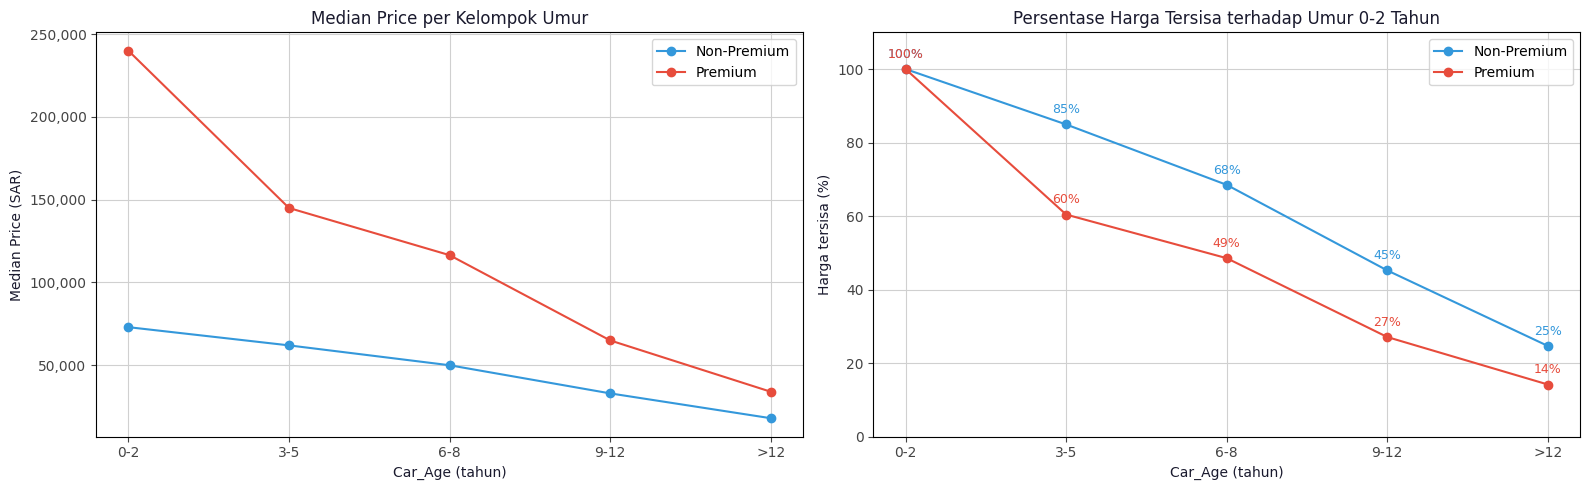

In [71]:
age_segment = (df_mv.groupby(['Age_Group', 'Segment'], observed=True)['Price']
                    .median().unstack())
retention = age_segment / age_segment.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
palette = {'Non-Premium': BLUE, 'Premium': RED}

for seg in ['Non-Premium', 'Premium']:
    axes[0].plot(age_segment.index.astype(str), age_segment[seg],
                 marker='o', color=palette[seg], label=seg)
    axes[1].plot(retention.index.astype(str), retention[seg] * 100,
                 marker='o', color=palette[seg], label=seg)
    for x, v in zip(retention.index.astype(str), retention[seg]):
        axes[1].annotate(f'{v:.0%}', (x, v * 100), textcoords='offset points',
                         xytext=(0, 8), ha='center', fontsize=9, color=palette[seg])

axes[0].yaxis.set_major_formatter(sar_fmt)
axes[0].set_title('Median Price per Kelompok Umur')
axes[0].set_xlabel('Car_Age (tahun)')
axes[0].set_ylabel('Median Price (SAR)')
axes[0].legend()

axes[1].set_title('Persentase Harga Tersisa terhadap Umur 0-2 Tahun')
axes[1].set_xlabel('Car_Age (tahun)')
axes[1].set_ylabel('Harga tersisa (%)')
axes[1].set_ylim(0, 110)
axes[1].legend()

plt.tight_layout()
plt.show()

Untuk melengkapi grafik yang dibuat berdasarkan median per kelompok umur, korelasi Spearman antara `Car_Age` dan `Price` dihitung pada setiap segmen menggunakan seluruh listing. Nilai ρ menunjukkan seberapa konsisten harga menurun seiring bertambahnya umur mobil pada masing-masing segmen.

In [72]:
results = []
for seg, group in df_mv.groupby('Segment'):
    rho, p = stats.spearmanr(group['Car_Age'], group['Price'])
    results.append({'Segment': seg, 'n': len(group), 'Spearman ρ': round(rho, 3), 'p-value': p})

pd.DataFrame(results)

,Segment,n,Spearman ρ,p-value
0,Non-Premium,4598,-0.481,1.030220e-264
1,Premium,889,-0.703,2.714365e-133


Hasil analisis menunjukkan bahwa `Car_Age` dan segmen merek saling berinteraksi dalam memengaruhi harga. Mobil premium memang selalu lebih mahal dibandingkan mobil non-premium pada setiap kelompok umur, tetapi harganya turun jauh lebih cepat. Pada umur 3–5 tahun, mobil premium hanya mempertahankan sekitar 60% dari harga mobil berumur 0–2 tahun, sedangkan mobil non-premium masih mempertahankan 85%. Pola ini berlanjut hingga mobil berumur lebih dari 12 tahun, dengan sisa harga 14% pada mobil premium dan 25% pada mobil non-premium.

Perbedaan ini juga terlihat dari kekuatan korelasinya. Hubungan `Car_Age` dengan `Price` pada segmen Premium tergolong kuat (ρ = −0,703), sedangkan pada segmen Non-Premium tergolong sedang (ρ = −0,481). Artinya, umur mobil menjadi faktor yang jauh lebih menentukan harga pada mobil premium. Akibatnya, selisih harga antara kedua segmen semakin menyempit seiring bertambahnya umur mobil, dari sekitar 3,3 kali lipat pada umur 0–2 tahun menjadi sekitar 1,9 kali lipat pada umur lebih dari 12 tahun.

Temuan ini menunjukkan bahwa pengaruh umur terhadap harga tidak sama untuk setiap mobil, melainkan bergantung pada segmen mereknya. Model yang dapat menangkap interaksi antar fitur, seperti model berbasis tree, berpotensi lebih sesuai untuk data ini. Sementara itu, model linear membutuhkan fitur interaksi tambahan agar dapat menangkap pola yang sama.

#### **1.3.2 Pengaruh Jarak Tempuh pada Mobil dengan Umur yang Sama**

Pada bagian 1.2.1, `Mileage` memiliki hubungan negatif dengan `Price` (ρ = −0,424). Namun, `Mileage` juga berkorelasi kuat dengan `Car_Age` (ρ = 0,68), karena mobil yang lebih tua umumnya sudah menempuh jarak lebih jauh. Akibatnya, sebagian hubungan antara `Mileage` dan `Price` bisa jadi sebenarnya berasal dari pengaruh umur mobil. Bagian ini memeriksa apakah `Mileage` tetap memengaruhi harga ketika umur mobil dibuat sama.

Pemeriksaan dilakukan dengan dua cara. Pertama, korelasi Spearman antara `Mileage` dan `Price` dihitung secara terpisah pada setiap kelompok umur, sehingga mobil yang dibandingkan memiliki umur yang relatif sama. Hipotesis dan tingkat signifikansi yang digunakan sama seperti pada bagian 1.2.1. Kedua, dihitung korelasi parsial Spearman, yaitu korelasi antara `Mileage` dan `Price` setelah pengaruh `Car_Age` dihilangkan dari keduanya. Perhitungan hanya menggunakan listing yang memiliki nilai `Mileage`.

In [73]:
data_mileage = df_mv.dropna(subset=['Mileage'])

results = []
for age, group in data_mileage.groupby('Age_Group', observed=True):
    rho, p = stats.spearmanr(group['Mileage'], group['Price'])
    results.append({
        'Age_Group': age,
        'n': len(group),
        'Spearman ρ': round(rho, 3),
        'p-value': p,
        'Keputusan': 'Tolak H0' if p < 0.05 else 'Gagal tolak H0',
    })

mileage_by_age = pd.DataFrame(results)
mileage_by_age

,Age_Group,n,Spearman ρ,p-value,Keputusan
0,0-2,995,-0.367,4.025400e-33,Tolak H0
1,3-5,2068,-0.228,8.848645e-26,Tolak H0
2,6-8,1122,-0.232,4.043875e-15,Tolak H0
3,9-12,489,-0.130,3.993303e-03,Tolak H0
4,>12,426,-0.065,1.797981e-01,Gagal tolak H0


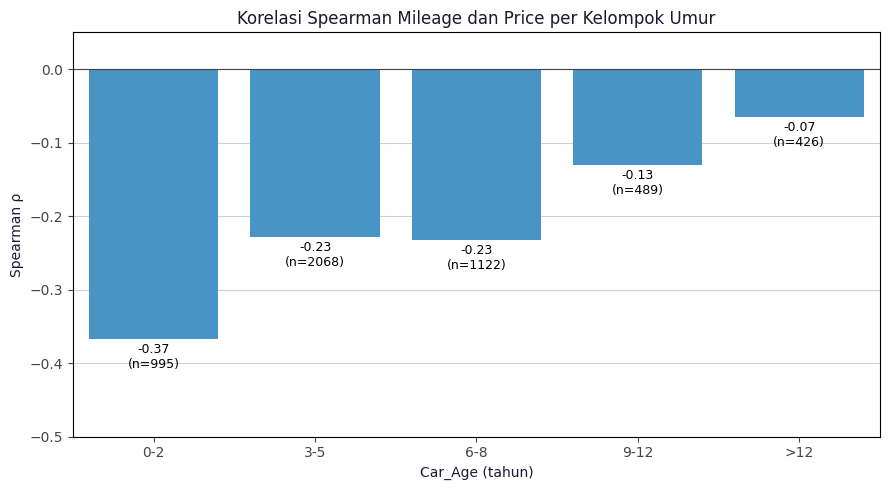

In [74]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(data=mileage_by_age, x='Age_Group', y='Spearman ρ', color=BLUE, ax=ax)
ax.bar_label(ax.containers[0],
             labels=[f"{r:.2f}\n(n={n})" for r, n in zip(mileage_by_age['Spearman ρ'], mileage_by_age['n'])],
             padding=3, fontsize=9)
ax.axhline(0, color='#444444', linewidth=0.8)
ax.set_ylim(-0.5, 0.05)
ax.set_title('Korelasi Spearman Mileage dan Price per Kelompok Umur')
ax.set_xlabel('Car_Age (tahun)')
ax.set_ylabel('Spearman ρ')

plt.tight_layout()
plt.show()

In [75]:
def remove_effect(y, x):
    """Menghilangkan pengaruh linear x dari y dan mengembalikan residualnya.

    Args:
        y (pd.Series): Variabel yang akan dihilangkan pengaruhnya.
        x (pd.Series): Variabel pengontrol.

    Returns:
        pd.Series: Residual y setelah pengaruh x dihilangkan.
    """
    slope, intercept = np.polyfit(x, y, 1)
    return y - (slope * x + intercept)


# Korelasi parsial Spearman: data diubah menjadi peringkat, lalu pengaruh Car_Age dihilangkan
ranked = data_mileage[['Mileage', 'Price', 'Car_Age']].rank()
resid_mileage = remove_effect(ranked['Mileage'], ranked['Car_Age'])
resid_price = remove_effect(ranked['Price'], ranked['Car_Age'])

rho_partial, p_partial = stats.pearsonr(resid_mileage, resid_price)
rho_raw, _ = stats.spearmanr(data_mileage['Mileage'], data_mileage['Price'])

print(f"Jumlah listing                          : {len(data_mileage)}")
print(f"Spearman Mileage vs Price               : {rho_raw:.3f}")
print(f"Spearman parsial (mengontrol Car_Age)   : {rho_partial:.3f} (p-value = {p_partial:.2e})")

Jumlah listing                          : 5100
Spearman Mileage vs Price               : -0.424
Spearman parsial (mengontrol Car_Age)   : -0.191 (p-value = 5.18e-43)


Setelah umur mobil dikontrol, hubungan antara `Mileage` dan `Price` melemah cukup besar. Korelasi Spearman turun dari −0,424 menjadi −0,191 setelah pengaruh `Car_Age` dihilangkan, sehingga tergolong sangat lemah berdasarkan acuan Evans (1996). Artinya, lebih dari separuh hubungan `Mileage` dengan `Price` yang terlihat pada bagian 1.2.1 sebenarnya berasal dari pengaruh umur mobil. Meskipun demikian, korelasi parsial ini masih signifikan (p-value < 0,05), sehingga `Mileage` tetap memberikan informasi tambahan tentang harga yang tidak tercakup oleh `Car_Age`.

Hasil per kelompok umur juga menunjukkan bahwa pengaruh `Mileage` tidak sama untuk setiap umur mobil. Pengaruh terkuat terlihat pada mobil berumur 0–2 tahun (ρ = −0,367), lalu melemah pada umur 3–8 tahun (ρ sekitar −0,23) dan 9–12 tahun (ρ = −0,130). Pada mobil berumur lebih dari 12 tahun, hubungan ini tidak lagi signifikan (p-value = 0,180), sehingga H0 gagal ditolak. Dengan kata lain, jarak tempuh sangat diperhatikan pada mobil yang masih baru, tetapi hampir tidak berpengaruh lagi pada mobil yang sudah tua, karena harga mobil tua lebih ditentukan oleh umurnya.

Berdasarkan hasil ini, `Mileage` tetap dipertahankan sebagai fitur karena memberikan informasi yang berbeda dari `Car_Age`. Namun, karena pengaruhnya bergantung pada umur mobil, hubungan ini merupakan bentuk interaksi lain yang dapat ditangkap dengan baik oleh model berbasis tree.

#### **1.3.3 Pemeriksaan Multikolinearitas Antar Fitur**

Pada bagian 1.2.1 ditemukan bahwa `Car_Age` dan `Mileage` saling berkorelasi kuat (ρ = 0,68). Untuk memastikan apakah korelasi ini menimbulkan multikolinearitas, dihitung Variance Inflation Factor (VIF) pada fitur numerik. VIF mengukur seberapa besar suatu fitur dapat dijelaskan oleh gabungan fitur numerik lainnya. Berbeda dengan heatmap korelasi yang hanya melihat hubungan antar dua fitur, VIF juga dapat menangkap multikolinearitas yang melibatkan lebih dari dua fitur sekaligus. Perhitungan hanya menggunakan listing yang tidak memiliki nilai kosong pada ketiga fitur numerik. Acuan interpretasi nilai VIF yang digunakan adalah sebagai berikut:

| Rentang VIF | Interpretasi |
|---|---|
| VIF < 5 | Aman, multikolinearitas rendah |
| VIF 5–10 | Mulai perlu diwaspadai |
| VIF > 10 | Multikolinearitas tinggi, bermasalah untuk model yang sensitif terhadap ini (misal regresi linear) |

In [76]:
x_vif = sm.add_constant(df[num_cols].dropna())

vif_score = pd.DataFrame({
    'Feature': num_cols,
    'VIF': [variance_inflation_factor(x_vif.values, i) for i in range(1, x_vif.shape[1])],
}).round(2)

print(f"Jumlah listing yang digunakan: {len(x_vif)}")
vif_score

Jumlah listing yang digunakan: 4074


,Feature,VIF
0,Car_Age,1.50
1,Mileage,1.47
2,Engine_Size,1.06


VIF dihitung dari 4.074 listing yang memiliki nilai lengkap pada ketiga fitur numerik. Seluruh fitur memiliki nilai VIF di bawah 2, yaitu `Car_Age` 1,50, `Mileage` 1,47, dan `Engine_Size` 1,06, sehingga tergolong aman berdasarkan acuan di atas. Artinya, meskipun `Car_Age` dan `Mileage` saling berkorelasi kuat, hubungan tersebut tidak cukup besar untuk menimbulkan multikolinearitas. Dengan demikian, ketiga fitur numerik dapat digunakan bersama dalam model, termasuk model linear, tanpa perlu menghapus atau menggabungkan fitur.

### **1.4 Ringkasan Temuan dan Implikasinya untuk Modeling**

Tabel berikut merangkum hasil pengujian hubungan setiap fitur dengan `Price` pada bagian 1.2, diurutkan berdasarkan kekuatan hubungannya. Seluruh fitur memiliki hubungan yang signifikan secara statistik (p-value < 0,05), sehingga kekuatan hubungan dinilai dari effect size masing-masing uji. Karena setiap uji menggunakan ukuran effect size yang berbeda, perbandingan antar fitur dilakukan berdasarkan kategori kekuatannya, bukan nilai angkanya secara langsung.

| Fitur | Jenis | Uji | Effect size | Kekuatan |
|---|---|---|---|---|
| `Type` | Kategorikal | Kruskal-Wallis | ε² = 0,518 | Besar |
| `Make` | Kategorikal | Kruskal-Wallis | ε² = 0,255 | Sedang (mendekati besar) |
| `Car_Age` | Numerik | Spearman | ρ = −0,475 | Sedang |
| `Engine_Size` | Numerik | Spearman | ρ = 0,454 | Sedang |
| `Mileage` | Numerik | Spearman | ρ = −0,424 | Sedang |
| `Options` | Kategorikal | Kruskal-Wallis | ε² = 0,125 | Sedang |
| `Gear_Type` | Kategorikal | Mann-Whitney U | r = 0,284 | Kecil |
| `Origin` | Kategorikal | Kruskal-Wallis | ε² = 0,038 | Kecil |
| `Region` | Kategorikal | Kruskal-Wallis | ε² = 0,027 | Kecil |
| `Color` | Kategorikal | Kruskal-Wallis | ε² = 0,024 | Kecil |
| `Fuel_Type` | Kategorikal | Kruskal-Wallis | ε² = 0,004 | Sangat kecil |

Faktor yang paling menentukan harga mobil bekas pada dataset ini adalah model dan merek kendaraan, diikuti oleh umur, ukuran mesin, jarak tempuh, dan tingkat kelengkapan fitur. Sebaliknya, warna, wilayah penjualan, asal kendaraan, dan jenis bahan bakar hanya memiliki pengaruh kecil terhadap harga. Analisis multivariat pada bagian 1.3 juga menunjukkan bahwa pengaruh beberapa fitur tidak berdiri sendiri. Penurunan harga akibat umur lebih cepat pada mobil premium, pengaruh jarak tempuh melemah seiring bertambahnya umur mobil, dan sebagian besar hubungan `Mileage` dengan `Price` sebenarnya berasal dari pengaruh umur. Meskipun `Car_Age` dan `Mileage` saling berkorelasi kuat, nilai VIF seluruh fitur numerik berada di bawah 2, sehingga tidak terjadi multikolinearitas.

Selain itu, perbandingan pada bagian 1.1.4 menunjukkan bahwa listing Negotiable memiliki karakteristik kendaraan yang sebanding dengan listing berharga, sehingga asumsi pada bagian Business Understanding terpenuhi. Namun, listing Negotiable cenderung berisi mobil yang lebih tua dan memiliki lebih banyak nilai kosong.

Berdasarkan temuan tersebut, berikut implikasi yang akan diterapkan pada tahap modeling:

| Aspek | Temuan EDA | Implikasi untuk Modeling |
|---|---|---|
| Target | `Price` sangat condong ke kanan (skewness 3,74) | Target ditransformasi dengan log1p selama training dan dikembalikan dengan expm1 saat prediksi, sehingga metrik evaluasi tetap dalam satuan SAR. Performa dengan dan tanpa transformasi akan dibandingkan. |
| Nilai kosong | `Engine_Size` (1.189 baris), `Mileage` (387), `Options` (39), `Origin` (26), dan `Gear_Type` (18) | Nilai kosong diimputasi di dalam pipeline setelah train-test split agar tidak terjadi data leakage. Karena `Mileage` sangat berkaitan dengan umur mobil, imputasi berdasarkan `Car_Age` dapat dipertimbangkan. |
| Fitur ordinal | `Options` memiliki pola harga berurutan (Standard < Semi Full < Full) | `Options` di-encode secara ordinal agar urutannya tetap terjaga. |
| Kardinalitas tinggi | `Type` (385 kategori) dan `Make` (60 kategori) memiliki pengaruh terbesar, tetapi banyak kategori yang jarang muncul | Kategori yang jarang perlu dikelompokkan atau menggunakan metode encoding yang sesuai untuk kardinalitas tinggi, agar model tidak overfitting pada kategori dengan sedikit listing. |
| Fitur dengan pengaruh kecil | `Fuel_Type` hampir tidak membedakan harga (ε² = 0,004), dan pengaruh `Color` sebagian berasal dari umur mobil | Fitur-fitur ini tetap disertakan pada model awal, lalu kontribusinya dievaluasi melalui feature importance. |
| Multikolinearitas | VIF seluruh fitur numerik di bawah 2 | Seluruh fitur numerik dapat digunakan bersama tanpa perlu dihapus atau digabung. |
| Interaksi antar fitur | Pengaruh umur bergantung pada segmen merek, dan pengaruh jarak tempuh bergantung pada umur | Model berbasis tree berpotensi lebih sesuai karena dapat menangkap interaksi secara otomatis. Jika menggunakan model linear, diperlukan fitur interaksi tambahan. |
| Penerapan pada listing Negotiable | Karakteristik kendaraan sebanding dengan listing berharga, tetapi proporsi mobil berumur lebih dari 12 tahun dua kali lipat (21,7% dibandingkan 9,8%) dan nilai kosong `Engine_Size` mencapai 40,1% | Model dapat diterapkan untuk memberikan estimasi harga pasar bagi listing Negotiable. Performa model perlu dievaluasi secara khusus pada segmen mobil berumur tua, dan estimasi sebaiknya disajikan dalam bentuk rentang harga. |

Dengan demikian, hasil EDA tidak hanya menggambarkan karakteristik data, tetapi juga menjadi dasar pengambilan keputusan pada tahap preprocessing dan pemilihan model.